# Claude's ingratiation and withdrawal by user motivation and user state (Oxford subset)

**Data:** [Anthropic/enabling-independent-research](https://huggingface.co/datasets/Anthropic/enabling-independent-research), subset `oxford` (CC BY 4.0).
**Background:** [Enabling independent research on how people use Claude](https://www.anthropic.com/news/enabling-independent-research) and its appendix.

This notebook inspects, validates, analyses and visualises the data. It contains no interpretation; interpretation is in `report.md`, and supporting tables are in `supplementary.md`.

**What the notebook does**
1. Loads the Oxford subset and records a fingerprint of the raw table.
2. Inspects and validates its structure (facets, levels, cross-tab columns, suppressed cells).
3. Describes the behaviour facet `model_ingratiation_withdrawal` and how its labels co-occur with six other behaviour facets.
4. Compares the eight level-1 motivation groups on ingratiation/withdrawal (Figure 1).
5. Selects eleven user-state scales and cross-tabulates ingratiation/withdrawal with each of them (Figures 2 and 3).
6. Compares the eight motivation groups on four other behaviour facets (Figure 4).
7. Checks at the end that the raw data was never modified.

## Contents
1. [Setup](#1.-Setup)
2. [Loading the data](#2.-Loading-the-data)
3. [Structure of the Oxford subset](#3.-Structure-of-the-Oxford-subset)
4. [Validation checks](#4.-Validation-checks)
5. [The behaviour facet: ingratiation / withdrawal](#5.-The-behaviour-facet:-ingratiation-/-withdrawal)
6. [Ingratiation / withdrawal × motivation](#6.-Ingratiation-/-withdrawal-×-motivation)
7. [Selecting user-state scales](#7.-Selecting-user-state-scales)
8. [Ingratiation / withdrawal × user states](#8.-Ingratiation-/-withdrawal-×-user-states)
9. [Motivation × four other behaviour facets](#9.-Motivation-×-four-other-behaviour-facets)
10. [Integrity check and list of outputs](#10.-Integrity-check-and-list-of-outputs)

### Terms used throughout
- **Facet:** a question that a Claude model answered about every conversation (column `facet_id`). The questions were written by the Oxford researchers; the answers were produced by a Claude model through Anthropic Insights.
- **Cluster (row):** one row of the table is one cluster of conversations that received a similar answer to one facet, not one conversation.
- **Level:** level 0 = the most specific clusters; level 1 = broader parent groups that contain level-0 clusters. The same conversations appear at both levels, so levels are never added together. Exception: for `user_motivational_open` the published level-1 groups contain fewer conversations than level 0 (see section 6).
- **Cross-tab column:** `facet:value_statistic`, for example `user_happy:5_num_records` = how many conversations in this cluster were rated 5 on `user_happy`.
- **Suppressed cell:** an empty cross-tab cell. The combination was hidden for privacy (too few conversations) or not computed. It is not a zero.
- **Two-way tables only:** every cross-tab relates exactly two facets. The data cannot select conversations that have two labels at once (for example a motivation group *and* ingratiation), so all results are associations between two facets at a time.

## 1. Setup

### Imports and versions
All libraries are imported here. The printed versions are the ones the notebook was last run with; `requirements.txt` lists the same packages.

In [1]:
import hashlib
import sys
import textwrap
from importlib.metadata import version
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from matplotlib.colors import LinearSegmentedColormap, to_rgb

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 120)

print(f"python      {sys.version.split()[0]}")
for package in ["pandas", "numpy", "matplotlib", "datasets", "jinja2"]:
    print(f"{package:<11} {version(package)}")

d:\Turing\demo-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


python      3.14.5
pandas      3.0.6
numpy       2.5.4
matplotlib  3.11.2
datasets    5.2.0
jinja2      3.1.6


### Constants
Every fixed choice of the analysis is defined once here (names in CAPITALS are not changed later in the notebook).

| Group | Constants | Meaning |
|---|---|---|
| Data | `DATASET_ID`, `SUBSET` | Hugging Face dataset and the subset used |
| Output | `OUTPUT_DIR`, `TABLE_DIR`, `FIGURE_DIR` | relative folders, so the notebook runs on any computer |
| Categories | `NA`, `SCALE_VALUES`, `SCALE_ORDER` | label of the "not applicable" answer and the order of the 1–6 rating scale |
| Behaviour | `BEHAVIOR`, `BEHAVIOR_CATEGORIES`, `BEHAVIOR_PAIR` | the analysed behaviour facet, its categories in display order, and the two opposite labels |
| Other behaviour | `LABEL_FACETS` | six behaviour facets used to describe what ingratiation and withdrawal contain (section 5) |
| Other behaviour | `PROFILE_FACETS` | four behaviour facets compared across motivation groups (section 9), each with its categories in display order |
| Groups | `GROUP_FACET`, `N_GROUPS` | the open facet whose level-1 groups are compared, and their expected number |
| User states | `USER_SCALES`, `EXCLUDED_USER_SCALES` | user scales analysed and excluded (selection in section 7) |
| Thresholds | `MIN_POINT`, `N_TOP_CELLS` | fixed before the results were seen (see the table below) |
| Display | `SHOW_DESCRIPTIONS` | `True` prints the cluster descriptions of all user facets (long output) |

| Threshold | Value | Used for |
|---|---|---|
| `MIN_POINT` | 500 | minimum number of conversations behind one point in the rating-line figure (Figure 3) |
| `N_TOP_CELLS` | 3 | number of cells with the largest absolute residual kept per table (`top_cells`); the first is the pair of the strongest association |

In [2]:
DATASET_ID = "Anthropic/enabling-independent-research"
SUBSET = "oxford"

OUTPUT_DIR = Path("outputs")
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"

NA = "not_applicable"
SCALE_VALUES = ["1", "2", "3", "4", "5", "6"]
SCALE_ORDER = SCALE_VALUES + [NA]

BEHAVIOR = "model_ingratiation_withdrawal"
BEHAVIOR_CATEGORIES = ["ingratiation", "mixed", NA, "withdrawal"]
BEHAVIOR_PAIR = ("ingratiation", "withdrawal")

LABEL_FACETS = [
    "model_flattery_challenge",
    "model_encouragement_discouragement",
    "model_assent_dissent",
    "model_espousal_facts_norms",
    "model_conformism_eccentricity",
    "model_refusal_compliance",
]
PROFILE_FACETS = {
    "model_flattery_challenge": ["flattery", "mixed", NA, "challenge"],
    "model_assent_dissent": ["assent", NA, "dissent"],
    "model_conformism_eccentricity": ["conformism", NA, "eccentricity"],
    "model_refusal_compliance": ["refusal", NA, "compliance"],
}

GROUP_FACET = "user_motivational_open"
N_GROUPS = 8

USER_SCALES = [
    "user_frustrated", "user_happy", "user_feel_good", "user_curious", "user_enjoyment_average",
    "user_enjoyment_change", "user_entertained", "user_bored", "user_tired", "user_unproductive",
    "user_absorbed",
]
EXCLUDED_USER_SCALES = [
    "user_recommend_to_friend", "user_recommend_to_future_self", "user_return_in_own_time",
    "user_prefer_not_to_visit_again", "user_challenged",
]

MIN_POINT = 500
N_TOP_CELLS = 3
SHOW_DESCRIPTIONS = False

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

### Plot style
Colours and names shared by all figures. Heatmaps (Figures 1 and 4) use blue for above the whole sample and red for below, with a light grey midpoint. In Figure 2, blue marks a positive gap and orange a negative one; in Figure 3, blue marks positive user states and orange negative ones.

In [3]:
INK, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"

CATEGORY_NAMES = {NA: "n/a"}  # display names; other categories are shown as they are
FACET_TITLES = {
    "model_flattery_challenge": "Flattery / challenge",
    "model_assent_dissent": "Assent / dissent",
    "model_conformism_eccentricity": "Conformism / eccentricity",
    "model_refusal_compliance": "Refusal / compliance",
}
DIVERGING = LinearSegmentedColormap.from_list("below_above", ["#e34948", "#f0efec", BLUE])
STATE_GROUPS = {  # colour groups for the rating-line figure
    "positive": ["happy", "feel_good", "enjoyment_average", "enjoyment_change",
                 "entertained", "curious", "absorbed"],
    "negative": ["frustrated", "bored", "tired", "unproductive"],
}
GROUP_COLORS = {"positive": BLUE, "negative": ORANGE}


def style_axes(ax: plt.Axes) -> None:
    """Apply the shared look: surface background, no frame, muted tick labels.

    :param ax: axes to style
    """
    ax.set_facecolor(SURFACE)
    ax.tick_params(colors=MUTED, length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)


def text_color_on(fill) -> str:
    """Choose white text on dark fills and ink on light fills.

    :param fill: any matplotlib colour (hex string or RGBA tuple)
    :return: "white" or the INK colour
    """
    r, g, b = to_rgb(fill)
    return "white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.45 else INK


def save_figure(fig: plt.Figure, name: str) -> None:
    """Save a figure as PNG in FIGURE_DIR and show it.

    :param fig: the figure
    :param name: file name without extension
    """
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=200, facecolor=fig.get_facecolor())
    plt.show()

## 2. Loading the data

`load_oxford` downloads the subset from Hugging Face once and reads it from the local cache afterwards. `fingerprint` turns the whole table (values, index and column names) into one 12-character code. The code is stored right after loading and compared again in section 10, which shows that no cell modified the raw table. All later cells read from `OX` and never write into it.

In [4]:
def load_oxford() -> pd.DataFrame:
    """Download (or read from cache) the Oxford subset.

    :return: the raw table, exactly as published
    """
    return load_dataset(DATASET_ID, SUBSET, split="train").to_pandas()


def fingerprint(df: pd.DataFrame) -> str:
    """Return a short hash of a full table (values, index and column names).

    :param df: any DataFrame
    :return: first 12 characters of a SHA-256 hash
    """
    row_hashes = pd.util.hash_pandas_object(df, index=True).to_numpy()
    digest = hashlib.sha256(row_hashes.tobytes())
    digest.update("|".join(df.columns).encode("utf-8"))
    return digest.hexdigest()[:12]


OX = load_oxford()
RAW_FINGERPRINT = fingerprint(OX)
print(f"{len(OX)} rows, {OX.shape[1]} columns, fingerprint {RAW_FINGERPRINT}")

472 rows, 310 columns, fingerprint 41aa7efc2753


## 3. Structure of the Oxford subset

### Base columns
Columns without a colon describe the cluster itself. `.info()` shows their types and missing values.

| column | meaning (from the dataset card) |
|---|---|
| `cluster_id` | unique id of the cluster |
| `facet_id` | the question (facet) the cluster belongs to |
| `cluster_name`, `cluster_description` | Claude-written label and summary of the cluster; for fixed-answer facets the name is the answer option and the description is empty |
| `level` | 0 = most specific clusters, 1 = parent groups |
| `num_records` | number of conversations in the cluster |
| `num_orgs` | number of distinct accounts/organisations in the cluster |
| `ratio`, `ratio_95ci_lower`, `ratio_95ci_upper` | the cluster's share of the sample, with 95% CI |
| `mean_val`, `sum_val` | filled only for numeric facets (none in Oxford) |
| `sparkline`, `freq_slope` | not documented on the dataset card; not used |

In [5]:
def is_crosstab(column: str) -> bool:
    """Cross-tab columns are the only ones with a colon in their name.

    :param column: a column name
    """
    return ":" in column


BASE_COLUMNS = [c for c in OX.columns if not is_crosstab(c)]
OX[BASE_COLUMNS].info()

<class 'pandas.DataFrame'>
RangeIndex: 472 entries, 0 to 471
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   cluster_id           472 non-null    str    
 1   facet_id             472 non-null    str    
 2   cluster_name         472 non-null    str    
 3   cluster_description  322 non-null    str    
 4   level                472 non-null    int64  
 5   num_records          472 non-null    int64  
 6   ratio                472 non-null    float64
 7   ratio_95ci_lower     472 non-null    float64
 8   ratio_95ci_upper     472 non-null    float64
 9   num_orgs             472 non-null    int64  
dtypes: float64(3), int64(3), str(4)
memory usage: 187.0 KB


The first five rows of the base columns.

In [6]:
OX[BASE_COLUMNS].head()

,cluster_id,facet_id,cluster_name,cluster_description,level,num_records,ratio,ratio_95ci_lower,ratio_95ci_upper,num_orgs
0,user_happy:1,user_happy,1,NaN,0,1483,0.006030,0.005724,0.006336,1483
1,user_happy:2,user_happy,2,NaN,0,11434,0.046493,0.045661,0.047326,11427
2,user_happy:3,user_happy,3,NaN,0,11091,0.045099,0.044279,0.045919,11088
3,user_happy:4,user_happy,4,NaN,0,36968,0.150321,0.148909,0.151734,36909
4,user_happy:5,user_happy,5,NaN,0,53612,0.218000,0.216368,0.219632,53529


### Facets: clusters per level and conversations covered
`facet_overview` counts clusters per facet and level, and sums `num_records` and `ratio` over level 0. A level-0 ratio sum close to 1 means every conversation received exactly one answer to that facet. Facets ending in `_open` are open-ended questions (free-text answers grouped into many clusters, with level-1 parent groups); the others are fixed-answer questions.

In [7]:
def facet_overview(df: pd.DataFrame) -> pd.DataFrame:
    """Clusters per facet and level, plus conversations and ratio summed at level 0.

    :param df: the Oxford table
    :return: one row per facet
    """
    counts = df.pivot_table(
        index="facet_id", columns="level", values="cluster_id", aggfunc="count", fill_value=0
    ).add_prefix("clusters_level_")
    level0 = df.loc[df["level"] == 0].groupby("facet_id").agg(
        conversations_level0=("num_records", "sum"),
        ratio_sum_level0=("ratio", "sum"),
    )
    return counts.join(level0).round(3).sort_values("clusters_level_0", ascending=False)


FACETS = facet_overview(OX)
FACETS.to_csv(TABLE_DIR / "01_facet_overview.csv", encoding="utf-8-sig")
FACETS

,clusters_level_0,clusters_level_1,conversations_level0,ratio_sum_level0
facet_id,,,,
user_motivational_open,174,8,245248,0.997
topic_open,134,6,243836,0.991
topic_category,8,0,245925,1.000
user_absorbed,7,0,245927,1.000
user_enjoyment_change,7,0,245927,1.000
user_frustrated,7,0,245927,1.000
user_entertained,7,0,245927,1.000
user_feel_good,7,0,245927,1.000
user_curious,7,0,245927,1.000


### Anatomy of the cross-tab columns
Every cross-tab column name has three parts: **facet : value _ statistic**. `split_value_and_stat` separates the value from the statistic by matching known suffixes, longest first, so that a suffix like `_mean_95ci_lower` is matched before `_mean_val`. `parse_crosstab_columns` applies it to every column. The result has one row per cross-tab column and is used to count values per facet and to locate missing cells.

In [8]:
STAT_SUFFIXES = [  # longest first
    "_mean_95ci_lower", "_mean_95ci_upper", "_sum_95ci_lower", "_sum_95ci_upper",
    "_num_records", "_stdev_val", "_mean_val", "_sum_val", "_ratio",
]


def split_value_and_stat(rest: str) -> tuple[str, str]:
    """Split 'clear_failure_ratio' into ('clear_failure', 'ratio').

    :param rest: the part of a column name after the colon
    :return: (value, statistic); statistic is "unknown" if no suffix matches
    """
    for suffix in STAT_SUFFIXES:
        if rest.endswith(suffix):
            return rest[: -len(suffix)], suffix.lstrip("_")
    return rest, "unknown"


def parse_crosstab_columns(df: pd.DataFrame) -> pd.DataFrame:
    """One row per cross-tab column: column name, facet, value, statistic.

    :param df: the Oxford table
    """
    rows = []
    for column in df.columns:
        if is_crosstab(column):
            facet, rest = column.split(":", 1)
            value, stat = split_value_and_stat(rest)
            rows.append({"column": column, "facet": facet, "value": value, "statistic": stat})
    return pd.DataFrame(rows)


CROSSTAB = parse_crosstab_columns(OX)
print(f"{len(CROSSTAB)} cross-tab columns for {CROSSTAB['facet'].nunique()} facets")
CROSSTAB.head(10)

300 cross-tab columns for 26 facets


,column,facet,value,statistic
0,user_happy:1_num_records,user_happy,1,num_records
1,user_happy:1_ratio,user_happy,1,ratio
2,user_happy:2_num_records,user_happy,2,num_records
3,user_happy:2_ratio,user_happy,2,ratio
4,user_happy:3_num_records,user_happy,3,num_records
5,user_happy:3_ratio,user_happy,3,ratio
6,user_happy:4_num_records,user_happy,4,num_records
7,user_happy:4_ratio,user_happy,4,ratio
8,user_happy:5_num_records,user_happy,5,num_records
9,user_happy:5_ratio,user_happy,5,ratio


### Values and missing cells per cross-tab facet
For each facet that appears as cross-tab columns: its answer values and the share of its count cells (`_num_records`) that are empty. Open-ended facets do not appear as cross-tab columns; they exist only as rows.

In [9]:
def crosstab_summary(cols: pd.DataFrame, df: pd.DataFrame) -> pd.DataFrame:
    """One row per cross-tab facet: number of values, the values, and the share of empty cells.

    :param cols: output of parse_crosstab_columns
    :param df: the Oxford table
    """
    rows = []
    for facet, group in cols.groupby("facet"):
        count_columns = group.loc[group["statistic"] == "num_records", "column"]
        values = sorted(group["value"].unique())
        rows.append({
            "facet": facet,
            "n_values": len(values),
            "values": ", ".join(values),
            "missing_share": round(df[count_columns].isna().to_numpy().mean(), 3),
        })
    return pd.DataFrame(rows).set_index("facet")


CROSSTAB_FACETS = crosstab_summary(CROSSTAB, OX)
CROSSTAB_FACETS.to_csv(TABLE_DIR / "02_crosstab_facets.csv", encoding="utf-8-sig")
CROSSTAB_FACETS

,n_values,values,missing_share
facet,,,
model_assent_dissent,3,"assent, dissent, not_applicable",0.014
model_concrete_abstract,4,"abstract_principles, concrete_examples, mixed, not_applicable",0.073
model_conformism_eccentricity,3,"conformism, eccentricity, not_applicable",0.030
model_encouragement_discouragement,4,"discouragement, encouragement, mixed, not_applicable",0.094
model_espousal_facts_norms,4,"espousal_of_facts, espousal_of_norms, mixed, not_applicable",0.044
model_flattery_challenge,4,"challenge, flattery, mixed, not_applicable",0.037
model_ingratiation_withdrawal,4,"ingratiation, mixed, not_applicable, withdrawal",0.037
model_neutral_opinionated,3,"neutral_stance, not_applicable, opinionated_stance",0.038
model_refusal_compliance,3,"compliance, not_applicable, refusal",0.089


### Missing cells by cluster size
`missing_by_cluster_size` splits the level-0 clusters into four equal-sized groups by `num_records` (quartiles) and reports the average share of empty count cells in each group. If small clusters have more empty cells, missingness depends on cluster size (rare combinations are suppressed first).

**Handling of suppressed cells in this notebook (Supplementary S4):** empty cells are kept empty (`NaN`) in every saved table and shown as hatched cells in Figure 4. Only where a calculation needs complete numbers (Cramér's V, residuals, shares) are they treated as 0. The number of affected cells is printed in sections 6, 8 and 9. A possible improvement, described in the Anthropic appendix but **not applied here**, is to recover a suppressed count by subtraction when the categories of a facet are exhaustive (cluster total minus the visible categories).

In [10]:
def missing_by_cluster_size(df: pd.DataFrame, cols: pd.DataFrame) -> pd.DataFrame:
    """Share of empty count cells for each quartile of cluster size (level 0 only).

    :param df: the Oxford table
    :param cols: output of parse_crosstab_columns
    """
    count_columns = cols.loc[cols["statistic"] == "num_records", "column"]
    level0 = df.loc[df["level"] == 0]
    size_group = pd.qcut(level0["num_records"], q=4, duplicates="drop")
    missing_share = level0[count_columns].isna().mean(axis="columns")
    return (
        missing_share.groupby(size_group, observed=True)
        .agg(["mean", "count"])
        .rename(columns={"mean": "missing_share", "count": "clusters"})
        .round(3)
    )


missing_by_cluster_size(OX, CROSSTAB)

,missing_share,clusters
num_records,,
"(55.999, 657.75]",0.405,115
"(657.75, 1715.5]",0.231,114
"(1715.5, 6606.75]",0.143,114
"(6606.75, 238913.0]",0.064,115


## 4. Validation checks

Each `assert` stops the notebook with a message if the data does not have the structure the analysis relies on. If every check passes, the cell prints one line.

| Check | Why it is needed |
|---|---|
| every cross-tab column was parsed | no column is silently ignored |
| every fixed facet used exists as rows and as cross-tab columns | the cross-tabulations need both |
| fixed facets: level-0 ratios sum to 1 (±0.02) | each conversation has exactly one answer per facet |
| the behaviour facets have exactly the expected categories | category names are hard-coded in `BEHAVIOR_CATEGORIES` and `PROFILE_FACETS` |
| the eleven user scales have exactly 1–6 and `not_applicable` | the scale order is hard-coded in `SCALE_ORDER` |
| the motivation facet has `N_GROUPS` level-1 groups | sections 6 and 9 use level 1 only |

In [11]:
def facet_categories(df: pd.DataFrame, facet: str) -> set[str]:
    """Names of the level-0 clusters of one facet (= its answer options for fixed facets).

    :param df: the Oxford table
    :param facet: facet id
    """
    return set(df.loc[(df["facet_id"] == facet) & (df["level"] == 0), "cluster_name"])


unparsed = CROSSTAB.loc[CROSSTAB["statistic"] == "unknown", "column"].tolist()
assert not unparsed, f"unparsed cross-tab columns: {unparsed}"

used_fixed = [BEHAVIOR] + LABEL_FACETS + USER_SCALES
for facet in used_fixed:
    assert facet in FACETS.index, f"{facet} missing as rows"
    assert facet in CROSSTAB_FACETS.index, f"{facet} missing as cross-tab columns"
    ratio_sum = FACETS.loc[facet, "ratio_sum_level0"]
    assert abs(ratio_sum - 1) <= 0.02, f"{facet}: level-0 ratios sum to {ratio_sum}"

assert facet_categories(OX, BEHAVIOR) == set(BEHAVIOR_CATEGORIES), f"{BEHAVIOR}: unexpected categories"
for facet, categories in PROFILE_FACETS.items():
    assert facet in LABEL_FACETS, f"{facet} is not validated above"
    assert facet_categories(OX, facet) == set(categories), f"{facet}: unexpected categories"

for facet in USER_SCALES:
    assert facet_categories(OX, facet) == set(SCALE_ORDER), f"{facet}: not a 1-6 + n/a scale"

n_groups = FACETS.loc[GROUP_FACET, "clusters_level_1"]
assert n_groups == N_GROUPS, f"{GROUP_FACET}: {n_groups} level-1 groups, expected {N_GROUPS}"

print("All validation checks passed.")

All validation checks passed.


### Tests of the statistics helpers
The helpers below are used in sections 5–9. They are defined here and tested on small hand-made tables with known answers before they are applied to the data.

- `row_percent` converts counts to row percentages (each row sums to 100).
- `cramers_v` measures the strength of association in a table of counts: 0 = no association, 1 = perfect association. It is $\sqrt{\chi^2 / (n \cdot (k-1))}$, where $\chi^2$ compares observed with expected counts, $n$ is the total count and $k$ is the smaller of the number of rows and columns.
- `adjusted_residuals` gives, for each cell, how far the observed count is above (+) or below (−) the count expected if the two facets were unrelated, in standard-error units. With n ≈ 246,000 these values are large and are used only to rank cells, not as tests.

In [12]:
def row_percent(counts: pd.DataFrame) -> pd.DataFrame:
    """Express each row as percentages of its own total.

    :param counts: table of counts
    """
    return counts.div(counts.sum(axis="columns"), axis="index") * 100


def cramers_v(counts: pd.DataFrame) -> float:
    """Cramér's V of a table of counts (0 = no association, 1 = perfect).

    :param counts: table of counts without empty cells
    """
    observed = counts.to_numpy(dtype=float)
    n = observed.sum()
    expected = observed.sum(axis=1, keepdims=True) * observed.sum(axis=0, keepdims=True) / n
    chi2 = ((observed - expected) ** 2 / expected).sum()
    k = min(observed.shape) - 1
    return float(np.sqrt(chi2 / (n * k))) if k > 0 else np.nan


def adjusted_residuals(counts: pd.DataFrame) -> pd.DataFrame:
    """Adjusted standardised residual of every cell (+ above, - below independence).

    :param counts: table of counts without empty cells
    """
    observed = counts.to_numpy(dtype=float)
    n = observed.sum()
    row = observed.sum(axis=1, keepdims=True)
    col = observed.sum(axis=0, keepdims=True)
    expected = row * col / n
    resid = (observed - expected) / np.sqrt(expected * (1 - row / n) * (1 - col / n))
    return pd.DataFrame(resid, index=counts.index, columns=counts.columns)


independent = pd.DataFrame([[10, 20], [30, 60]])
perfect = pd.DataFrame([[50, 0], [0, 50]])
assert np.isclose(cramers_v(independent), 0), "independent table should give V = 0"
assert np.isclose(cramers_v(perfect), 1), "perfect table should give V = 1"
assert np.allclose(row_percent(independent).sum(axis="columns"), 100)
assert np.allclose(adjusted_residuals(independent), 0)
print("Statistics helpers passed their tests.")

Statistics helpers passed their tests.


## 5. The behaviour facet: ingratiation / withdrawal

### All nine behaviour facets
Oxford asked nine questions about Claude's behaviour (facets starting with `model_`). The table shows, for each, the share of every answer in the whole sample, the share of `not_applicable`, and the share of its largest category. `selected` marks the facet analysed in this notebook (`BEHAVIOR`).

In [13]:
def behaviour_distribution(df: pd.DataFrame) -> pd.DataFrame:
    """Share (%) of each answer for every model_ facet, with n/a share and largest-category share.

    :param df: the Oxford table
    """
    model_facets = sorted(f for f in df["facet_id"].unique() if f.startswith("model_"))
    rows = {}
    for facet in model_facets:
        shares = (df.loc[(df["facet_id"] == facet) & (df["level"] == 0)]
                  .set_index("cluster_name")["ratio"] * 100)
        rows[facet] = {
            "answers": ", ".join(f"{name} {share:.1f}" for name, share in shares.sort_values(ascending=False).items()),
            "na_pct": round(shares.get(NA, 0), 1),
            "largest_pct": round(shares.drop(NA, errors="ignore").max(), 1),
            "selected": facet == BEHAVIOR,
        }
    return pd.DataFrame(rows).T.sort_values("largest_pct")


BEHAVIOUR_TABLE = behaviour_distribution(OX)
BEHAVIOUR_TABLE.to_csv(TABLE_DIR / "03_behaviour_facets.csv", encoding="utf-8-sig")
BEHAVIOUR_TABLE

,answers,na_pct,largest_pct,selected
model_flattery_challenge,"not_applicable 62.4, mixed 19.2, challenge 10.5, flattery 8.0",62.4,19.2,False
model_assent_dissent,"not_applicable 51.4, assent 32.5, dissent 16.2",51.4,32.5,False
model_ingratiation_withdrawal,"withdrawal 42.3, ingratiation 32.0, not_applicable 20.4, mixed 5.2",20.4,42.3,True
model_encouragement_discouragement,"encouragement 45.8, not_applicable 41.0, mixed 11.2, discouragement 2.0",41.0,45.8,False
model_neutral_opinionated,"opinionated_stance 56.5, neutral_stance 31.9, not_applicable 11.5",11.5,56.5,False
model_espousal_facts_norms,"espousal_of_facts 56.6, mixed 20.8, not_applicable 14.7, espousal_of_norms 7.9",14.7,56.6,False
model_concrete_abstract,"concrete_examples 62.7, mixed 22.1, not_applicable 12.2, abstract_principles 3.0",12.2,62.7,False
model_conformism_eccentricity,"conformism 72.2, eccentricity 14.4, not_applicable 13.4",13.4,72.2,False
model_refusal_compliance,"compliance 84.5, not_applicable 12.8, refusal 2.7",12.8,84.5,False


### What the labels contain
The fixed-answer facets have no descriptions, so the meaning of `ingratiation`, `mixed` and `withdrawal` is not documented. To describe them, the facet is cross-tabulated with six other behaviour facets (`LABEL_FACETS`). `count_table` builds a table of conversation counts with the categories of one facet as rows and the categories of another facet as columns, taken from the level-0 rows of the first facet and the cross-tab columns of the second. Empty (suppressed) cells stay empty. `share_table` turns it into row percentages.

All facets come from the same model judgement, so these tables show how the labels are applied together, not what Claude did in the conversations.

In [14]:
def count_table(df: pd.DataFrame, row_facet: str, col_facet: str) -> pd.DataFrame:
    """Conversation counts: categories of row_facet as rows, categories of col_facet as columns.

    Empty (suppressed) cells stay NaN; they are not zeros.

    :param df: the Oxford table
    :param row_facet: facet whose level-0 clusters become rows
    :param col_facet: facet whose cross-tab counts become columns
    """
    rows = df.loc[(df["facet_id"] == row_facet) & (df["level"] == 0)].set_index("cluster_name")
    prefix, suffix = f"{col_facet}:", "_num_records"
    cols = [c for c in df.columns if c.startswith(prefix) and c.endswith(suffix)]
    table = rows[cols].copy()
    table.columns = [c.removeprefix(prefix).removesuffix(suffix) for c in cols]
    order = [c for c in SCALE_ORDER if c in table.columns]
    table = table[order + [c for c in table.columns if c not in order]]
    table.index.name, table.columns.name = row_facet, col_facet
    return table.sort_index()


def share_table(df: pd.DataFrame, row_facet: str, col_facet: str) -> pd.DataFrame:
    """Row percentages of count_table (empty cells left out of the row totals).

    :param df: the Oxford table
    :param row_facet: facet whose categories become rows
    :param col_facet: facet whose categories become columns
    """
    counts = count_table(df, row_facet, col_facet)
    return row_percent(counts.fillna(0)).where(counts.notna()).round(1)


for other in LABEL_FACETS:
    table = share_table(OX, BEHAVIOR, other)
    table.to_csv(TABLE_DIR / f"04_label_meaning__x__{other.removeprefix('model_')}.csv", encoding="utf-8-sig")
    print(f"\n===== {BEHAVIOR} × {other} (row %) =====")
    display(table)


===== model_ingratiation_withdrawal × model_flattery_challenge (row %) =====


model_flattery_challenge,not_applicable,challenge,flattery,mixed
model_ingratiation_withdrawal,,,,
ingratiation,35.4,5.2,19.1,40.3
mixed,42.2,17.6,3.2,36.9
not_applicable,92.0,3.2,2.0,2.8
withdrawal,71.0,17.1,3.0,8.9



===== model_ingratiation_withdrawal × model_encouragement_discouragement (row %) =====


model_encouragement_discouragement,not_applicable,discouragement,encouragement,mixed
model_ingratiation_withdrawal,,,,
ingratiation,8.8,0.6,76.9,13.6
mixed,21.0,3.4,40.1,35.4
not_applicable,69.3,0.5,26.8,3.4
withdrawal,54.1,3.7,32.1,10.1



===== model_ingratiation_withdrawal × model_assent_dissent (row %) =====


model_assent_dissent,not_applicable,assent,dissent
model_ingratiation_withdrawal,,,
ingratiation,33.2,46.6,20.1
mixed,32.5,30.9,36.6
not_applicable,75.4,20.6,4.0
withdrawal,55.8,27.7,16.6


... (2 outputs left out)


===== model_ingratiation_withdrawal × model_conformism_eccentricity (row %) =====


model_conformism_eccentricity,not_applicable,conformism,eccentricity
model_ingratiation_withdrawal,,,
ingratiation,4.9,73.7,21.5
mixed,1.0,80.0,19.0
not_applicable,29.3,61.9,8.7
withdrawal,13.8,75.1,11.2



===== model_ingratiation_withdrawal × model_refusal_compliance (row %) =====


model_refusal_compliance,not_applicable,compliance,refusal
model_ingratiation_withdrawal,,,
ingratiation,7.8,90.3,1.9
mixed,4.7,86.6,8.7
not_applicable,29.0,70.5,0.5
withdrawal,9.8,86.6,3.6


### Label profile
The six tables above combined into one profile: rows = the categories of the six other behaviour facets (grouped by facet), columns = `ingratiation`, `mixed`, `not_applicable`, `withdrawal`, values = % of the conversations with that column label that received the row label. Within each block of rows (one other facet), each column sums to 100. This is the table shown in Supplementary S3.

In [15]:
def label_profile(df: pd.DataFrame, behavior: str, others: list[str]) -> pd.DataFrame:
    """Share (%) of each category of the other behaviour facets within each category of `behavior`.

    :param df: the Oxford table
    :param behavior: selected behaviour facet (its categories become columns)
    :param others: other behaviour facets (their categories become rows)
    :return: rows = (other facet, category), columns = categories of `behavior`
    """
    blocks = {other.removeprefix("model_"): share_table(df, behavior, other).T for other in others}
    profile = pd.concat(blocks, names=["other_facet", "category"])
    return profile[BEHAVIOR_CATEGORIES]


LABEL_PROFILE = label_profile(OX, BEHAVIOR, LABEL_FACETS)
LABEL_PROFILE.to_csv(TABLE_DIR / "04_label_profile.csv", encoding="utf-8-sig")
LABEL_PROFILE

model_ingratiation_withdrawal                   ingratiation  mixed  \
other_facet                  category                                 
flattery_challenge           not_applicable             35.4   42.2   
                             challenge                   5.2   17.6   
                             flattery                   19.1    3.2   
                             mixed                      40.3   36.9   
encouragement_discouragement not_applicable              8.8   21.0   
                             discouragement              0.6    3.4   
                             encouragement              76.9   40.1   
                             mixed                      13.6   35.4   
assent_dissent               not_applicable             33.2   32.5   
                             assent                     46.6   30.9   
                             dissent                    20.1   36.6   
espousal_facts_norms         not_applicable              5.7    0.7   
                             espousal_of_facts          46.3   53.2   
                             espousal_of_norms          13.9    6.8   
                             mixed                      34.1   39.4   
conformism_eccentricity      not_applicable              4.9    1.0   
                             conformism                 73.7   80.0   
                             eccentricity               21.5   19.0   
refusal_compliance           not_applicable              7.8    4.7   
                             compliance                 90.3   86.6   
                             refusal                     1.9    8.7   

model_ingratiation_withdrawal                   not_applicable  withdrawal  
other_facet                  category                                       
flattery_challenge           not_applicable               92.0        71.0  
                             challenge                     3.2        17.1  
                             flattery                      2.0         3.0  
                             mixed                         2.8         8.9  
encouragement_discouragement not_applicable               69.3        54.1  
                             discouragement                0.5         3.7  
                             encouragement                26.8        32.1  
                             mixed                         3.4        10.1  
assent_dissent               not_applicable               75.4        55.8  
                             assent                       20.6        27.7  
                             dissent                       4.0        16.6  
espousal_facts_norms         not_applicable               33.3        14.3  
                             espousal_of_facts            54.8        65.6  
                             espousal_of_norms             2.6         6.1  
                             mixed                         9.3        14.0  
conformism_eccentricity      not_applicable               29.3        13.8  
                             conformism                   61.9        75.1  
                             eccentricity                  8.7        11.2  
refusal_compliance           not_applicable               29.0         9.8  
                             compliance                   70.5        86.6  
                             refusal                       0.5         3.6

## 6. Ingratiation / withdrawal × motivation

`user_motivational_open` (why the user is in the conversation) is an open-ended facet. It is used at **level 1** only: eight groups, each with a Claude-written name and description. Level-0 clusters are not used.

According to the Anthropic appendix, open-ended clusters come from an automatic grouping that would differ in a rerun, every conversation is placed in exactly one cluster, and an open-ended question forces an answer for every conversation (there is no `not_applicable` option). Group sizes and percentages are therefore approximate. The level-1 groups of this facet contain fewer conversations than the subset total (see `01_facet_overview.csv` and the sum of the group sizes below); the missing conversations are absent from the published table. The dataset does not say why. The Anthropic appendix reports that Anthropic "redacted or removed 3.33% of clusters accounting for 3.85% of conversations" across the Oxford outputs during its privacy review; this figure is cited from the appendix and is not computed in this notebook.

### The eight motivation groups
Each group with its size and Claude-written description (report Section 3.3). The table is saved as `05_motivation_groups.csv`.

In [16]:
LEVEL1 = OX.loc[(OX["facet_id"] == GROUP_FACET) & (OX["level"] == 1)].set_index("cluster_name")
MOTIVATION_GROUPS = (
    LEVEL1[["num_records", "ratio", "cluster_description"]]
    .rename(columns={"num_records": "conversations", "ratio": "share", "cluster_description": "description"})
    .sort_values("conversations", ascending=False)
)
MOTIVATION_GROUPS["share"] = (MOTIVATION_GROUPS["share"] * 100).round(1)
MOTIVATION_GROUPS.to_csv(TABLE_DIR / "05_motivation_groups.csv", encoding="utf-8-sig")
for name, row in MOTIVATION_GROUPS.iterrows():
    print(f"\n{name}  ({row['conversations']:,} conversations, {row['share']}%)")
    print(textwrap.fill(str(row["description"]), width=110, initial_indent="    ", subsequent_indent="    "))


Detached pragmatic efficiency-seeking  (55,199 conversations, 22.4%)
    Users approached tasks with a predominantly calm, detached, and pragmatic orientation, prioritizing
    efficiency, goal completion, and practical problem-solving over emotional engagement. The subjective
    experience ranged from methodical control-seeking and cost-conscious deliberation to resignation,
    disillusionment, and pressured urgency, all unified by a transactional, utilitarian mindset.

Impatient task frustration  (52,930 conversations, 21.5%)
    These clusters captured a broad range of frustration, impatience, and urgency experienced by users during
    task execution, often involving AI interactions, technical challenges, deadlines, or communication
    breakdowns. The emotional states ranged from mild impatience and efficiency-seeking to escalating
    exasperation, mental exhaustion, and resigned withdrawal.

Ambitious motivated enthusiasm  (47,055 conversations, 19.1%)
    Users exhibited str

### Shares of each label per group
`group_counts` takes the level-1 rows and the cross-tab counts of a behaviour facet. `behavior_mix` converts them to percentages of all categories (including `mixed` and `not_applicable`), sorts the groups by the share of ingratiation, and adds an `All` row for the whole sample (from the behaviour facet's own rows). `group_v` gives Cramér's V of the group × behaviour table, with and without `not_applicable`. The `assert` checks that every row sums to 100%.

In [17]:
def group_counts(df: pd.DataFrame, group_facet: str, behavior: str) -> pd.DataFrame:
    """Counts of each behaviour category within every level-1 group of an open facet.

    :param df: the Oxford table
    :param group_facet: open facet id
    :param behavior: behaviour facet id
    :return: rows = groups, columns = num_records + behaviour categories
    """
    rows = df.loc[(df["facet_id"] == group_facet) & (df["level"] == 1)].set_index("cluster_name")
    prefix, suffix = f"{behavior}:", "_num_records"
    cols = [c for c in df.columns if c.startswith(prefix) and c.endswith(suffix)]
    counts = rows[cols].copy()
    counts.columns = [c.removeprefix(prefix).removesuffix(suffix) for c in cols]
    counts.insert(0, "num_records", rows["num_records"])
    return counts


def behavior_mix(df: pd.DataFrame, group_facet: str, behavior: str) -> tuple[pd.DataFrame, pd.Series]:
    """Share (%) of every behaviour category per group, plus an 'All' row for the whole sample.

    :param df: the Oxford table
    :param group_facet: open facet id
    :param behavior: behaviour facet id
    :return: (percentages, conversations per row); groups sorted by the first category
    """
    order = BEHAVIOR_CATEGORIES
    counts = group_counts(df, group_facet, behavior)
    cats = counts[order].fillna(0)
    whole = df.loc[(df["facet_id"] == behavior) & (df["level"] == 0)].set_index("cluster_name")["num_records"]
    pct = row_percent(cats).sort_values(order[0])
    pct.loc["All"] = whole[order] / whole[order].sum() * 100
    sizes = counts["num_records"].reindex(pct.index)
    sizes.loc["All"] = whole.sum()
    return pct.round(1), sizes


def group_v(df: pd.DataFrame, group_facet: str, behavior: str) -> tuple[float, float]:
    """Cramér's V of the group × behaviour table: (all categories, not_applicable removed).

    :param df: the Oxford table
    :param group_facet: open facet id
    :param behavior: behaviour facet id
    """
    cats = group_counts(df, group_facet, behavior).drop(columns="num_records").fillna(0)
    return cramers_v(cats), cramers_v(cats.drop(columns=NA))


MIX, MIX_SIZES = behavior_mix(OX, GROUP_FACET, BEHAVIOR)
assert np.allclose(MIX.sum(axis="columns"), 100, atol=0.5), "shares do not sum to 100"
n_suppressed = int(group_counts(OX, GROUP_FACET, BEHAVIOR)[BEHAVIOR_CATEGORIES].isna().to_numpy().sum())
MIX.assign(conversations=MIX_SIZES).to_csv(TABLE_DIR / "06_motivation_x_ingratiation.csv", encoding="utf-8-sig")

V_ALL, V_RATED = group_v(OX, GROUP_FACET, BEHAVIOR)
pd.DataFrame([{"V_all": round(V_ALL, 3), "V_rated_only": round(V_RATED, 3), "suppressed_cells": n_suppressed}]).to_csv(
    TABLE_DIR / "06_motivation_x_ingratiation_v.csv", index=False, encoding="utf-8-sig"
)
print(f"Cramér's V: all categories {V_ALL:.3f}, not_applicable removed {V_RATED:.3f}; "
      f"suppressed cells: {n_suppressed}")
MIX.assign(conversations=MIX_SIZES)

Cramér's V: all categories 0.176, not_applicable removed 0.184; suppressed cells: 0


,ingratiation,mixed,not_applicable,withdrawal,conversations
cluster_name,,,,,
Detached pragmatic efficiency-seeking,22.4,4.2,30.0,43.4,55199.0
Impatient task frustration,23.8,4.9,13.9,57.4,52930.0
Perfectionist quality anxiety,28.7,2.9,14.7,53.6,23912.0
Intellectual curiosity and wonder,33.6,6.2,34.9,25.3,24881.0
Anxiety and reassurance-seeking,41.9,8.2,15.9,34.0,32609.0
Ambitious motivated enthusiasm,43.5,4.7,17.3,34.5,47055.0
Acute overwhelm and distress,51.4,7.8,9.6,31.1,3570.0
Longing and emotional yearning,66.5,5.9,13.3,14.3,2442.0
All,32.0,5.2,20.4,42.3,245927.0


**Figure 1 — heatmap of differences.** Groups are ordered by the share of ingratiation, highest at the top. Each cell = the group's percentage − the whole sample's percentage for that label (percentage points; blue above, red below, symmetric colour scale). The whole-sample percentage of each label is printed under the column name. Each row sums to about zero, because both the group and the whole sample sum to 100%.

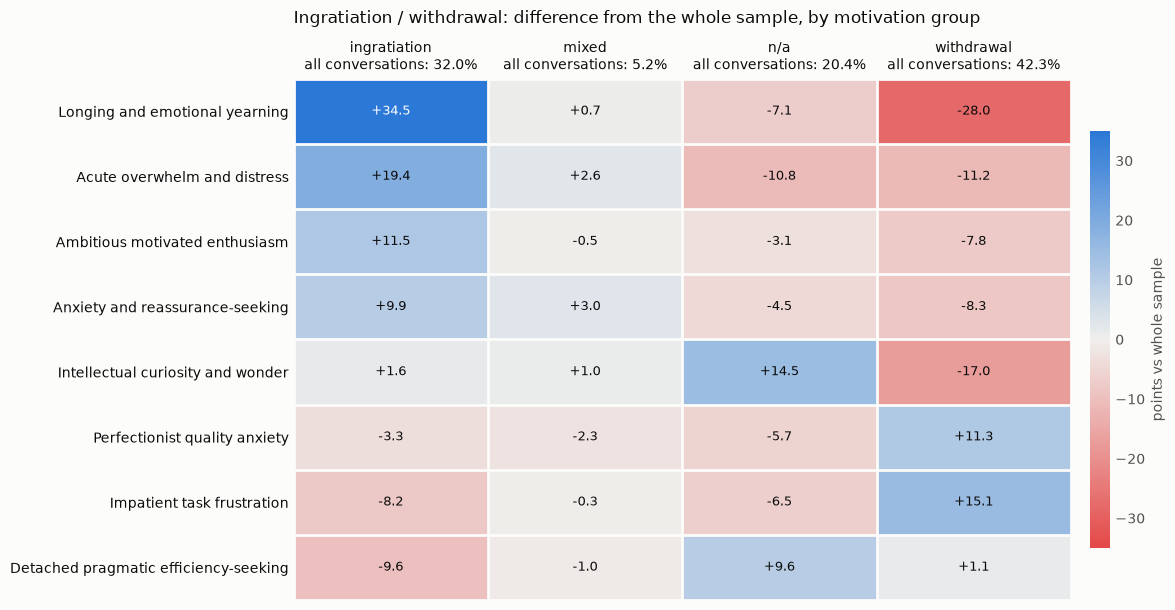

In [18]:
def deviation_heatmap_figure(pct: pd.DataFrame) -> plt.Figure:
    """Percentage points above (+) or below (-) the whole sample, per group and category.

    :param pct: percentages from behavior_mix
    """
    order = BEHAVIOR_CATEGORIES
    diff = (pct.drop(index="All") - pct.loc["All"])[order].iloc[::-1]  # highest first-label share on top
    limit = max(10, np.ceil(diff.abs().to_numpy().max() / 5) * 5)
    fig, ax = plt.subplots(figsize=(2.0 * len(order) + 4.5, 0.55 * len(diff) + 1.8), facecolor=SURFACE)
    style_axes(ax)
    image = ax.imshow(diff.to_numpy(), cmap=DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
    for i in range(diff.shape[0]):
        for j in range(diff.shape[1]):
            value = diff.iat[i, j]
            ax.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=9,
                    color=text_color_on(DIVERGING((value + limit) / (2 * limit))))
    headers = [f"{CATEGORY_NAMES.get(c, c)}\nall conversations: {pct.loc['All', c]:.1f}%" for c in order]
    ax.set_xticks(range(len(order)), headers, color=INK)
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(diff)), diff.index, color=INK)
    ax.set_xticks(np.arange(-0.5, len(order)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(diff)), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="minor", length=0)
    bar = fig.colorbar(image, ax=ax, shrink=0.8, pad=0.02)
    bar.set_label("points vs whole sample", color=MUTED)
    bar.ax.tick_params(colors=MUTED, length=0)
    bar.outline.set_visible(False)
    ax.set_title("Ingratiation / withdrawal: difference from the whole sample, by motivation group",
                 color=INK, loc="left", fontsize=12, pad=12)
    fig.tight_layout()
    return fig


fig = deviation_heatmap_figure(MIX)
save_figure(fig, "fig1_motivation_x_ingratiation")

## 7. Selecting user-state scales

Oxford asked sixteen fixed-answer questions about the user (facets starting with `user_`, excluding the open-ended `user_motivational_open`). Fifteen are rated 1–6 plus `not_applicable`; `user_challenged` is rated 1–4.

### Distribution of every user facet
Share of each answer in the whole sample. A large `not_applicable` share means that for most conversations the model did not rate that state.

In [19]:
ALL_USER_FACETS = sorted(
    f for f in OX["facet_id"].unique() if f.startswith("user_") and f != GROUP_FACET
)


def answer_shares(df: pd.DataFrame, facets: list[str]) -> pd.DataFrame:
    """Share (%) of each answer for each facet (rows = facets, columns = answers).

    :param df: the Oxford table
    :param facets: facet ids
    """
    level0 = df.loc[df["facet_id"].isin(facets) & (df["level"] == 0)]
    table = level0.pivot_table(index="facet_id", columns="cluster_name", values="ratio") * 100
    order = [c for c in SCALE_ORDER if c in table.columns]
    return table[order].round(1)


USER_DISTRIBUTION = answer_shares(OX, ALL_USER_FACETS)
USER_DISTRIBUTION.to_csv(TABLE_DIR / "07_user_facet_distribution.csv", encoding="utf-8-sig")
USER_DISTRIBUTION.sort_values(NA)

cluster_name,1,2,3,4,5,6,not_applicable
facet_id,,,,,,,
user_absorbed,2.2,18.4,7.9,15.5,37.1,13.2,5.8
user_curious,3.8,40.7,13.8,13.7,15.2,4.0,8.8
user_recommend_to_future_self,0.8,5.0,1.2,6.7,52.7,7.7,25.9
user_return_in_own_time,1.7,5.1,1.0,8.2,33.8,24.3,25.9
user_frustrated,22.6,23.0,5.6,6.9,2.2,0.5,39.3
user_recommend_to_friend,1.1,5.0,1.3,6.6,38.4,6.8,40.6
user_enjoyment_average,0.9,4.6,4.2,19.6,23.2,1.8,45.7
user_enjoyment_change,10.4,2.7,2.3,3.1,11.5,21.9,48.2
user_happy,0.6,4.6,4.5,15.0,21.8,0.9,52.5


### Cluster descriptions (optional)
`print_definitions` prints every cluster of a facet with its size and description. For fixed-answer facets the description is empty, which is why the scale direction is checked indirectly below. Set `SHOW_DESCRIPTIONS = True` in the constants to print them.

In [20]:
TEXT_WIDTH = 110


def print_definitions(df: pd.DataFrame, facet: str, level: int = 0) -> None:
    """Print every cluster of one facet with its size and description.

    :param df: the Oxford table
    :param facet: facet id
    :param level: cluster level to print
    """
    rows = df.loc[(df["facet_id"] == facet) & (df["level"] == level)].sort_values("cluster_name")
    print(f"\n{'=' * TEXT_WIDTH}\n{facet}  (level {level}, {len(rows)} clusters)\n{'=' * TEXT_WIDTH}")
    for _, row in rows.iterrows():
        print(f"\n--- {row['cluster_name']}  |  {row['num_records']:,} conversations ({row['ratio']:.1%})")
        description = row["cluster_description"]
        if pd.isna(description) or not str(description).strip():
            print("    (no description)")
        else:
            print(textwrap.fill(str(description), width=TEXT_WIDTH,
                                initial_indent="    ", subsequent_indent="    "))


if SHOW_DESCRIPTIONS:
    for facet in [BEHAVIOR] + ALL_USER_FACETS:
        print_definitions(OX, facet)
else:
    print("Descriptions not printed (SHOW_DESCRIPTIONS = False).")

Descriptions not printed (SHOW_DESCRIPTIONS = False).


### Direction of the 1–6 scales (known-groups check)
The scale anchors are not published. To check which end of a scale means "more of the state", the average rating of each scale is computed within the eight level-1 groups of `user_motivational_open`, whose descriptions are known (for example "Impatient task frustration", "Ambitious motivated enthusiasm"). If a group described as frustrated has the highest average on `user_frustrated`, a higher number means more frustration.

`mean_rating` treats the labels 1–6 as numbers and averages them over rated conversations only (`not_applicable` and empty cells are left out). This is used only to find the direction of a scale. `known_groups_table` builds the table: rows = motivation groups, columns = scales. The colour runs within each column (red = highest group, green = lowest).

In [21]:
def mean_rating(df: pd.DataFrame, facet: str) -> pd.Series:
    """Average 1-6 rating of a facet in each row, ignoring not_applicable and empty cells.

    :param df: rows of the Oxford table
    :param facet: a 1-6 user scale
    """
    counts = df[[f"{facet}:{v}_num_records" for v in SCALE_VALUES]]
    weights = np.array([int(v) for v in SCALE_VALUES])
    rated = counts.sum(axis="columns", min_count=1)
    return (counts * weights).sum(axis="columns", min_count=1) / rated


def known_groups_table(df: pd.DataFrame, group_facet: str, scales: list[str]) -> pd.DataFrame:
    """Mean rating of each scale within each level-1 group of an open facet.

    :param df: the Oxford table
    :param group_facet: open facet whose level-1 groups are used
    :param scales: 1-6 user scales
    """
    groups = df.loc[(df["facet_id"] == group_facet) & (df["level"] == 1)].set_index("cluster_name")
    return pd.DataFrame({s.removeprefix("user_"): mean_rating(groups, s) for s in scales}).round(2)


SIX_POINT_FACETS = [f for f in ALL_USER_FACETS if f != "user_challenged"]
KNOWN_GROUPS = known_groups_table(OX, GROUP_FACET, SIX_POINT_FACETS)
KNOWN_GROUPS.to_csv(TABLE_DIR / "07_known_groups_motivation.csv", encoding="utf-8-sig")
KNOWN_GROUPS.style.background_gradient(cmap="RdYlGn_r", axis="index").format("{:.2f}")

,absorbed,bored,curious,enjoyment_average,enjoyment_change,entertained,feel_good,frustrated,happy,prefer_not_to_visit_again,recommend_to_friend,recommend_to_future_self,return_in_own_time,tired,unproductive
cluster_name,,,,,,,,,,,,,,,
Intellectual curiosity and wonder,3.68,2.34,3.57,4.62,5.00,4.26,4.50,1.93,4.53,1.44,4.83,4.89,4.86,3.40,2.38
Perfectionist quality anxiety,4.79,1.83,3.25,4.38,4.61,3.87,4.57,1.88,4.45,2.25,4.81,4.93,5.24,3.13,1.74
Anxiety and reassurance-seeking,4.18,2.34,3.05,4.11,4.25,3.60,3.94,2.02,3.93,2.30,4.61,4.64,4.73,3.70,2.32
Detached pragmatic efficiency-seeking,3.57,2.56,2.74,4.36,4.59,3.66,4.49,1.83,4.44,2.24,4.81,4.90,4.90,3.23,1.96
Ambitious motivated enthusiasm,4.65,1.59,3.59,4.65,5.17,4.16,4.66,1.62,4.65,1.26,5.00,5.04,5.25,3.12,1.52
Impatient task frustration,4.04,3.13,2.77,3.56,3.30,3.06,3.92,2.58,3.67,4.19,4.10,4.32,4.59,3.83,2.99
Acute overwhelm and distress,4.47,2.38,2.68,3.55,3.73,3.03,3.32,2.47,3.21,2.95,4.55,4.48,4.66,4.28,2.95
Longing and emotional yearning,4.67,1.80,2.99,4.39,4.52,4.21,3.84,2.03,3.92,1.48,4.87,4.83,4.87,4.09,2.95


### Figure: known-groups heatmap
The same table drawn as a heatmap (Supplementary S1). Columns are ordered with the eleven selected scales first (negative states, then positive states) and the four excluded 1–6 scales to the right of the vertical line. `challenged` is not shown because it uses a 1–4 scale, so its mean is not comparable with the others. Colours are scaled within each column with `RdYlGn_r`: red = the motivation group with the highest average on that scale, green = the lowest.

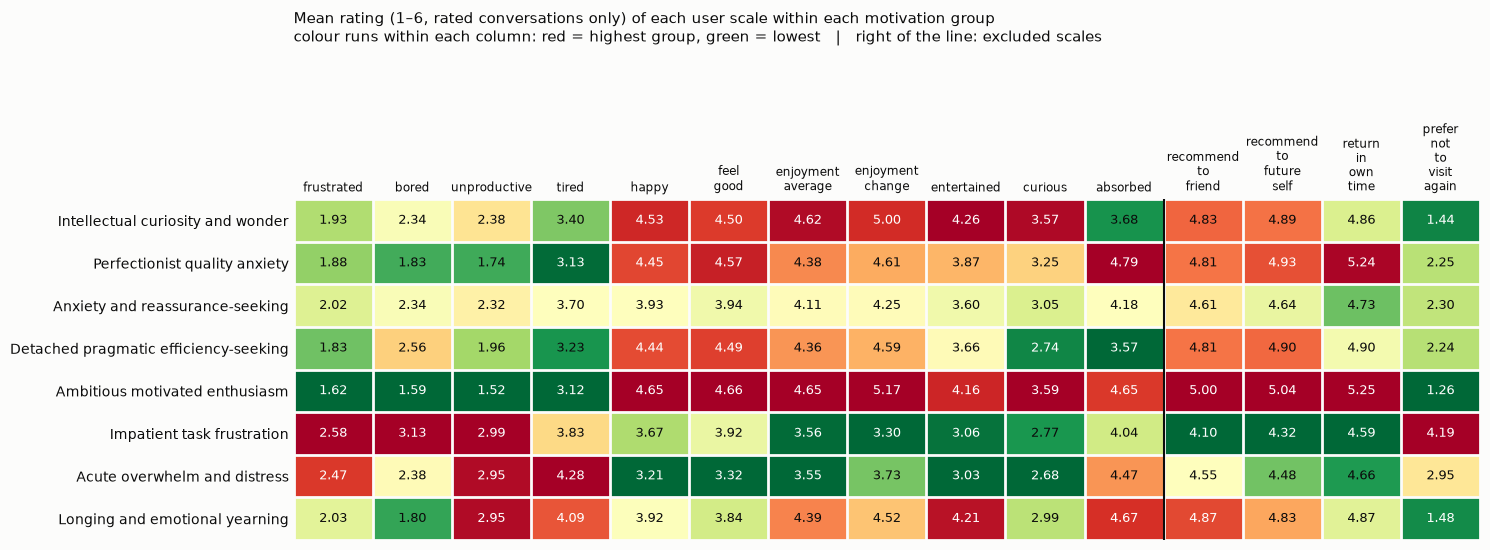

In [22]:
HEATMAP_COLUMNS = [
    "frustrated", "bored", "unproductive", "tired", "happy", "feel_good", "enjoyment_average",
    "enjoyment_change", "entertained", "curious", "absorbed",
    "recommend_to_friend", "recommend_to_future_self", "return_in_own_time", "prefer_not_to_visit_again",
]


def known_groups_figure(table: pd.DataFrame, columns: list[str], n_selected: int) -> plt.Figure:
    """Heatmap of mean ratings with colours scaled within each column.

    :param table: output of known_groups_table (columns without "user_")
    :param columns: column order; the first n_selected are the selected scales
    :param n_selected: number of selected scales (a line is drawn after them)
    """
    table = table[columns]
    scaled = (table - table.min()) / (table.max() - table.min())
    cmap = plt.get_cmap("RdYlGn_r")
    fig, ax = plt.subplots(figsize=(15, 5.6), facecolor=SURFACE)
    style_axes(ax)
    ax.imshow(scaled.to_numpy(), cmap=cmap, aspect="auto", vmin=0, vmax=1)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(j, i, f"{table.iat[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color=text_color_on(cmap(scaled.iat[i, j])))
    ax.set_xticks(range(len(columns)), [c.replace("_", "\n") for c in columns], fontsize=8.5, color=INK)
    ax.xaxis.tick_top()
    ax.set_yticks(range(len(table)), table.index, color=INK)
    ax.set_xticks(np.arange(-0.5, len(columns)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(table)), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="both", length=0)
    ax.axvline(n_selected - 0.5, color=INK, linewidth=1.5)
    ax.set_title("Mean rating (1–6, rated conversations only) of each user scale within each motivation group\n"
                 "colour runs within each column: red = highest group, green = lowest   |   "
                 "right of the line: excluded scales", loc="left", color=INK, fontsize=11, pad=58)
    fig.tight_layout()
    return fig


fig = known_groups_figure(KNOWN_GROUPS, HEATMAP_COLUMNS, n_selected=len(USER_SCALES))
save_figure(fig, "supp1_known_groups")

### Selected and excluded user scales (Supplementary S2)
`spread` is the difference between the highest and the lowest group average in the table above: how strongly a scale separates the eight motivation groups. The selection uses this table together with the distribution table:

| Decision | Scales | Reason |
|---|---|---|
| kept (11) | frustrated, happy, feel_good, curious, enjoyment_average, enjoyment_change, entertained, bored, tired, unproductive, absorbed | direction consistent with the group descriptions |
| excluded | recommend_to_friend, recommend_to_future_self, return_in_own_time | most group averages close together near the top of the scale (ceiling), small spread |
| excluded | prefer_not_to_visit_again | about 96% `not_applicable` |
| excluded | challenged | 1–4 scale, about 97% `not_applicable` |

Working reading of the categories used in section 8: `1` = the model saw evidence that the state was absent or minimal, `6` = strongly present, `not_applicable` = no evidence either way. `enjoyment_change` runs from 1 = enjoyment decreased to 6 = enjoyment increased. `not_applicable` is kept as its own category throughout.

In [23]:
SCALE_CHECK = pd.DataFrame({
    "spread": (KNOWN_GROUPS.max() - KNOWN_GROUPS.min()).round(2),
    "highest_group": KNOWN_GROUPS.idxmax(),
    "lowest_group": KNOWN_GROUPS.idxmin(),
    "na_pct": USER_DISTRIBUTION[NA].rename(lambda f: f.removeprefix("user_")),
})
SCALE_CHECK["selected"] = ["user_" + s in USER_SCALES for s in SCALE_CHECK.index]
SCALE_CHECK.to_csv(TABLE_DIR / "07_scale_selection.csv", encoding="utf-8-sig")
SCALE_CHECK.sort_values(["selected", "spread"], ascending=False)

,spread,highest_group,lowest_group,na_pct,selected
enjoyment_change,1.87,Ambitious motivated enthusiasm,Impatient task frustration,48.2,True
bored,1.54,Impatient task frustration,Ambitious motivated enthusiasm,71.9,True
unproductive,1.47,Impatient task frustration,Ambitious motivated enthusiasm,68.4,True
happy,1.44,Ambitious motivated enthusiasm,Acute overwhelm and distress,52.5,True
feel_good,1.34,Ambitious motivated enthusiasm,Acute overwhelm and distress,73.3,True
entertained,1.23,Intellectual curiosity and wonder,Acute overwhelm and distress,54.9,True
absorbed,1.22,Perfectionist quality anxiety,Detached pragmatic efficiency-seeking,5.8,True
tired,1.16,Acute overwhelm and distress,Ambitious motivated enthusiasm,77.8,True
enjoyment_average,1.10,Ambitious motivated enthusiasm,Acute overwhelm and distress,45.7,True
frustrated,0.96,Impatient task frustration,Ambitious motivated enthusiasm,39.3,True


## 8. Ingratiation / withdrawal × user states

`BEHAVIOR` is cross-tabulated with each of the eleven user scales (11 tables). Rows are the behaviour categories, columns are ratings 1–6 and `not_applicable`.

`analyse_pair` computes for one table:

| Output | Meaning |
|---|---|
| `counts` | conversation counts (empty cells kept empty) |
| `row_pct` | each behaviour category as row percentages |
| `residuals` | adjusted residuals of every cell |
| `V_all` | Cramér's V of the full table, `not_applicable` included on both sides |
| `V_rated_only` | Cramér's V with `not_applicable` removed from rows and columns |
| `top_cells` | the `N_TOP_CELLS` cells with the largest absolute residual |
| `coverage` | counted conversations / all conversations of the behaviour facet |
| `suppressed_cells` | number of empty cells in the table |

V is computed twice because conversations with little content can be `not_applicable` on both sides at once; `V_rated_only` measures the association between the actual behaviour labels and the actual ratings without that overlap.

In [24]:
def drop_na_categories(counts: pd.DataFrame) -> pd.DataFrame:
    """Remove not_applicable from both rows and columns.

    :param counts: table of counts
    """
    return counts.drop(index=NA, columns=NA, errors="ignore")


def analyse_pair(df: pd.DataFrame, behavior: str, scale: str) -> dict:
    """All numbers for one behaviour facet × user scale pair (see the table above).

    :param df: the Oxford table
    :param behavior: behaviour facet id
    :param scale: user scale id
    :return: dict with "summary" (one row of numbers), "counts", "row_pct", "residuals"
    """
    raw_counts = count_table(df, behavior, scale)
    rows_total = df.loc[(df["facet_id"] == behavior) & (df["level"] == 0), "num_records"].sum()
    counts = raw_counts.fillna(0)  # empty cells -> 0 only for the calculations
    rated = drop_na_categories(counts)
    resid = adjusted_residuals(counts)
    top = resid.stack().abs().sort_values(ascending=False).head(N_TOP_CELLS).index
    v_rated = cramers_v(rated)
    return {
        "summary": {
            "behavior": behavior,
            "user_scale": scale,
            "conversations": int(counts.to_numpy().sum()),
            "coverage": round(counts.to_numpy().sum() / rows_total, 3),
            "suppressed_cells": int(raw_counts.isna().to_numpy().sum()),
            "V_all": round(cramers_v(counts), 3),
            "V_rated_only": round(v_rated, 3),
            "top_cells": "; ".join(f"{r} x {c} ({resid.loc[r, c]:+.0f})" for r, c in top),
        },
        "counts": raw_counts,
        "row_pct": row_percent(counts).where(raw_counts.notna()).round(1),
        "residuals": resid.round(1),
    }


def save_pair(result: dict) -> None:
    """Write counts, row % and residuals of one pair to TABLE_DIR.

    :param result: output of analyse_pair
    """
    s = result["summary"]
    stem = f"{s['behavior'].removeprefix('model_')}__x__{s['user_scale'].removeprefix('user_')}"
    for part in ("counts", "row_pct", "residuals"):
        result[part].to_csv(TABLE_DIR / f"08_pair__{stem}__{part}.csv", encoding="utf-8-sig")

The loop runs `analyse_pair` for all eleven scales, saves three tables per scale and collects the summary rows into one table sorted by `V_rated_only`. The `assert` checks the expected table shape (4 behaviour categories × 7 answer columns).

In [25]:
PAIR_RESULTS = {}
for scale in USER_SCALES:
    result = analyse_pair(OX, BEHAVIOR, scale)
    expected_shape = (len(BEHAVIOR_CATEGORIES), len(SCALE_ORDER))
    assert result["counts"].shape == expected_shape, f"{scale}: unexpected shape"
    PAIR_RESULTS[scale] = result
    save_pair(result)

PAIR_SUMMARY = (
    pd.DataFrame([r["summary"] for r in PAIR_RESULTS.values()])
    .sort_values("V_rated_only", ascending=False)
    .reset_index(drop=True)
)
PAIR_SUMMARY.to_csv(TABLE_DIR / "08_pair_summary.csv", index=False, encoding="utf-8-sig")
print(f"{len(PAIR_RESULTS)} tables analysed, {PAIR_SUMMARY['suppressed_cells'].sum()} empty cells in total")
PAIR_SUMMARY

11 tables analysed, 2 empty cells in total


,behavior,user_scale,conversations,coverage,suppressed_cells,V_all,V_rated_only,top_cells
0,model_ingratiation_withdrawal,user_entertained,245927,1.0,0,0.269,0.287,ingratiation x not_applicable (-164); ingratiation x 5 (+147); not_applicable x not_applicable (+118)
1,model_ingratiation_withdrawal,user_enjoyment_change,245927,1.0,0,0.267,0.242,not_applicable x not_applicable (+158); ingratiation x not_applicable (-146); ingratiation x 6 (+138)
2,model_ingratiation_withdrawal,user_bored,245927,1.0,0,0.158,0.232,ingratiation x 1 (+104); not_applicable x not_applicable (+91); ingratiation x not_applicable (-71)
3,model_ingratiation_withdrawal,user_enjoyment_average,245927,1.0,0,0.267,0.222,ingratiation x not_applicable (-163); ingratiation x 5 (+154); not_applicable x not_applicable (+148)
4,model_ingratiation_withdrawal,user_happy,245927,1.0,0,0.246,0.187,ingratiation x not_applicable (-157); not_applicable x not_applicable (+148); ingratiation x 5 (+142)
5,model_ingratiation_withdrawal,user_unproductive,245927,1.0,0,0.167,0.167,not_applicable x not_applicable (+123); not_applicable x 1 (-79); ingratiation x 1 (+77)
6,model_ingratiation_withdrawal,user_feel_good,245913,1.0,2,0.232,0.155,ingratiation x not_applicable (-173); ingratiation x 5 (+138); not_applicable x not_applicable (+122)
7,model_ingratiation_withdrawal,user_curious,245927,1.0,0,0.163,0.153,not_applicable x not_applicable (+88); withdrawal x 2 (+56); ingratiation x not_applicable (-54)
8,model_ingratiation_withdrawal,user_frustrated,245927,1.0,0,0.198,0.152,not_applicable x not_applicable (+148); ingratiation x 1 (+77); not_applicable x 2 (-68)
9,model_ingratiation_withdrawal,user_absorbed,245927,1.0,0,0.205,0.110,not_applicable x not_applicable (+113); not_applicable x 5 (-89); not_applicable x 1 (+62)


Any single table can be inspected with its key, for example the row percentages for `user_frustrated`:

In [26]:
PAIR_RESULTS["user_frustrated"]["row_pct"]

user_frustrated,1,2,3,4,5,6,not_applicable
model_ingratiation_withdrawal,,,,,,,
ingratiation,32.1,24.6,4.7,4.6,1.5,0.2,32.4
mixed,22.3,30.6,7.3,6.9,2.2,0.3,30.4
not_applicable,13.1,11.6,2.6,3.4,0.7,0.6,68.0
withdrawal,20.1,26.4,7.5,10.2,3.5,0.6,31.7


### Association table
The user scales sorted by `V_rated_only` from highest to lowest. `strongest_pair` is the pair of the strongest association: the cell (behaviour category × user rating) with the largest absolute adjusted residual; the number in brackets is the residual, positive = more conversations than expected if the two facets were unrelated, negative = fewer. `strongest_involves_na` marks whether that pair includes `not_applicable` on either side.

In [27]:
def v_table(summary: pd.DataFrame, behavior: str) -> pd.DataFrame:
    """V values and the pair of the strongest association for one behaviour facet, sorted by V_rated_only.

    :param summary: PAIR_SUMMARY
    :param behavior: behaviour facet id
    """
    rows = summary.loc[summary["behavior"] == behavior].copy()
    rows["user_scale"] = rows["user_scale"].str.removeprefix("user_")
    rows["strongest_pair"] = rows["top_cells"].str.split("; ").str[0]
    rows["strongest_involves_na"] = rows["strongest_pair"].str.contains(NA)
    columns = ["user_scale", "V_all", "V_rated_only", "strongest_pair", "strongest_involves_na"]
    return rows[columns].sort_values("V_rated_only", ascending=False).reset_index(drop=True)


V_TABLE = v_table(PAIR_SUMMARY, BEHAVIOR)
V_TABLE.to_csv(TABLE_DIR / "08_v_table.csv", index=False, encoding="utf-8-sig")
n_na = int(V_TABLE["strongest_involves_na"].sum())
print(f"The pair of the strongest association involves not_applicable in {n_na} of {len(V_TABLE)} tables.")
V_TABLE

The pair of the strongest association involves not_applicable in 10 of 11 tables.


,user_scale,V_all,V_rated_only,strongest_pair,strongest_involves_na
0,entertained,0.269,0.287,ingratiation x not_applicable (-164),True
1,enjoyment_change,0.267,0.242,not_applicable x not_applicable (+158),True
2,bored,0.158,0.232,ingratiation x 1 (+104),False
3,enjoyment_average,0.267,0.222,ingratiation x not_applicable (-163),True
4,happy,0.246,0.187,ingratiation x not_applicable (-157),True
5,unproductive,0.167,0.167,not_applicable x not_applicable (+123),True
6,feel_good,0.232,0.155,ingratiation x not_applicable (-173),True
7,curious,0.163,0.153,not_applicable x not_applicable (+88),True
8,frustrated,0.198,0.152,not_applicable x not_applicable (+148),True
9,absorbed,0.205,0.110,not_applicable x not_applicable (+113),True


### Rated vs unrated user states
For each user scale, conversations are split into two parts: the state was **unrated** (`not_applicable`) or **rated** (1–6 combined). In each part, the share of ingratiation is computed **within the opposite pair**, with `mixed` and `not_applicable` behaviour labels left out: ingratiation share = ingratiation / (ingratiation + withdrawal). `share_by_rating_status` returns both shares, the number of conversations behind each, and their difference (`gap` = rated − unrated, in percentage points).

In [28]:
def share_by_rating_status(df: pd.DataFrame, behavior: str, scales: list[str]) -> pd.DataFrame:
    """Share (%) of the first label of BEHAVIOR_PAIR within the pair, for unrated and rated
    conversations of each user scale, and the gap between them.

    :param df: the Oxford table
    :param behavior: behaviour facet id
    :param scales: user scale ids
    :return: rows = scales (without "user_"), columns unrated, rated, conversation counts, gap
    """
    top, bottom = BEHAVIOR_PAIR
    rows = {}
    for scale in scales:
        counts = count_table(df, behavior, scale).fillna(0)
        unrated = counts[NA]
        rated = counts[SCALE_VALUES].sum(axis="columns")
        rows[scale.removeprefix("user_")] = {
            "unrated": unrated[top] / (unrated[top] + unrated[bottom]) * 100,
            "rated": rated[top] / (rated[top] + rated[bottom]) * 100,
            "unrated_conversations": unrated[top] + unrated[bottom],
            "rated_conversations": rated[top] + rated[bottom],
        }
    table = pd.DataFrame(rows).T
    table["gap"] = table["rated"] - table["unrated"]
    return table.round(1)


def gap_limits(table: pd.DataFrame) -> tuple[float, float]:
    """x-range of the gap figure, always including 0, with a margin for the value labels.

    :param table: output of share_by_rating_status
    """
    low, high = min(table["gap"].min(), 0), max(table["gap"].max(), 0)
    pad = 0.12 * (high - low)
    return low - pad, high + pad


GAP_TABLE = share_by_rating_status(OX, BEHAVIOR, USER_SCALES)
GAP_ORDER = GAP_TABLE.sort_values("gap").index
GAP_TABLE.reindex(GAP_ORDER[::-1]).to_csv(TABLE_DIR / "08_rated_vs_unrated.csv", encoding="utf-8-sig")
GAP_TABLE.reindex(GAP_ORDER[::-1])

,unrated,rated,unrated_conversations,rated_conversations,gap
feel_good,32.1,66.2,124250.0,58582.0,34.0
entertained,26.8,59.0,90666.0,92166.0,32.2
enjoyment_average,24.4,54.7,70289.0,112543.0,30.3
happy,28.2,55.2,82430.0,100402.0,27.0
enjoyment_change,28.4,53.0,73942.0,108890.0,24.6
curious,28.4,44.1,12073.0,170759.0,15.7
bored,39.7,50.0,123744.0,59088.0,10.2
absorbed,33.8,43.3,5694.0,177138.0,9.6
unproductive,41.4,45.7,114209.0,68623.0,4.3
frustrated,43.6,42.8,58494.0,124338.0,-0.9


**Figure 2 — gap.** One bar per user scale: rated share − unrated share. The x-axis is reversed so that a shift towards ingratiation points left. Blue = positive gap, orange = negative gap; the value is printed at the end of each bar.

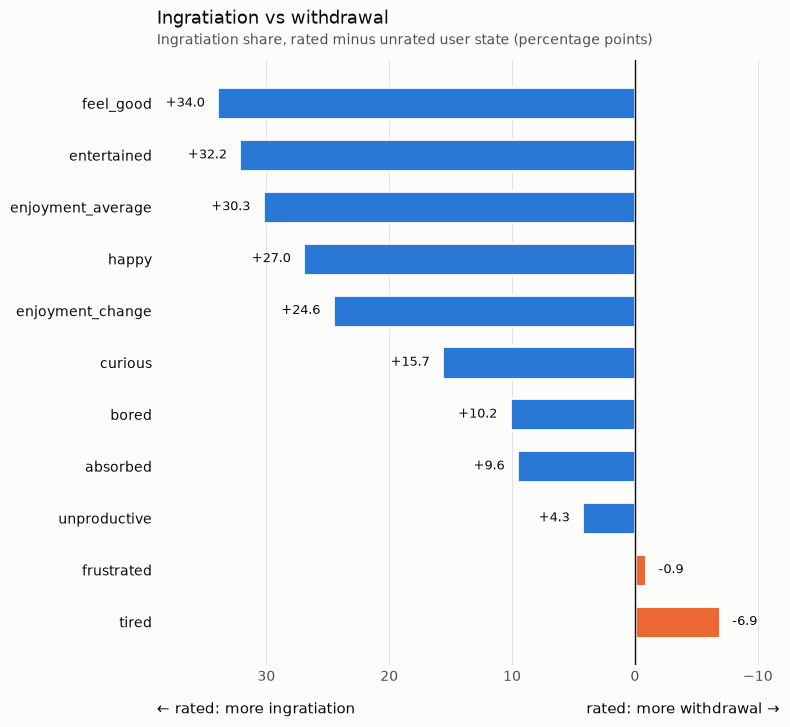

In [29]:
GAP_TEXT = {  # behaviour facet: (title, subtitle, label left, label right)
    "model_ingratiation_withdrawal": (
        "Ingratiation vs withdrawal",
        "Ingratiation share, rated minus unrated user state (percentage points)",
        "← rated: more ingratiation", "rated: more withdrawal →",
    ),
}


def gap_figure(table: pd.DataFrame, behavior: str, order: pd.Index,
               limits: tuple[float, float]) -> plt.Figure:
    """Horizontal bars of the rated - unrated gap per user scale, on a reversed x-axis.

    :param table: output of share_by_rating_status for one behaviour facet
    :param behavior: behaviour facet id
    :param order: row order (scales)
    :param limits: x-range
    """
    title, subtitle, left_label, right_label = GAP_TEXT[behavior]
    gaps = table["gap"].reindex(order)
    y = range(len(gaps))
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(order) + 2.4), facecolor=SURFACE)
    style_axes(ax)
    colors = [BLUE if v >= 0 else ORANGE for v in gaps]
    ax.barh(list(y), gaps.to_numpy(), color=colors, height=0.62, edgecolor=SURFACE, linewidth=2, zorder=2)
    ax.axvline(0, color=INK, linewidth=1, zorder=3)
    ax.set_xlim(limits[1], limits[0])  # reversed: positive values to the left
    offset = 0.02 * (limits[1] - limits[0])
    for yi, value in zip(y, gaps):
        ax.text(value + offset if value >= 0 else value - offset, yi, f"{value:+.1f}",
                va="center", ha="right" if value >= 0 else "left", fontsize=9, color=INK)
    ax.set_yticks(list(y), gaps.index, color=INK)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.text(0, -0.06, left_label, transform=ax.transAxes, ha="left", va="top", fontsize=11, color=INK)
    ax.text(1, -0.06, right_label, transform=ax.transAxes, ha="right", va="top", fontsize=11, color=INK)
    ax.set_title(title, loc="left", color=INK, fontsize=13, pad=26)
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, ha="left", va="bottom", fontsize=10, color=MUTED)
    fig.tight_layout()
    return fig


fig = gap_figure(GAP_TABLE, BEHAVIOR, GAP_ORDER, gap_limits(GAP_TABLE))
save_figure(fig, "fig2_rated_minus_unrated")

### Ingratiation by rating strength
Only rated conversations (1–6). For each user scale and each rating, the share of ingratiation and of withdrawal within the opposite pair (ingratiation / (ingratiation + withdrawal) and withdrawal / (ingratiation + withdrawal); `mixed` and `not_applicable` left out). The withdrawal panel is therefore the mirror image of the ingratiation panel (100 − ingratiation); both are drawn for readability. A point is drawn only when at least `MIN_POINT` conversations are behind it. Lines are coloured by `STATE_GROUPS` and labelled at their right end; labels are spread apart by `spread_labels` and joined to their line by a thin connector.

The dashed line in each panel is the same share computed over **all** conversations (for example ingratiation ÷ (ingratiation + withdrawal) over the whole sample); it is labelled "whole sample" in the column of line labels.

**Figure 3.** Each point is a different set of conversations, so a line compares groups of conversations with different ratings; it does not follow one conversation as a rating changes.

Whole-sample ingratiation share within the pair: 43.0%
Whole-sample withdrawal share within the pair: 57.0%


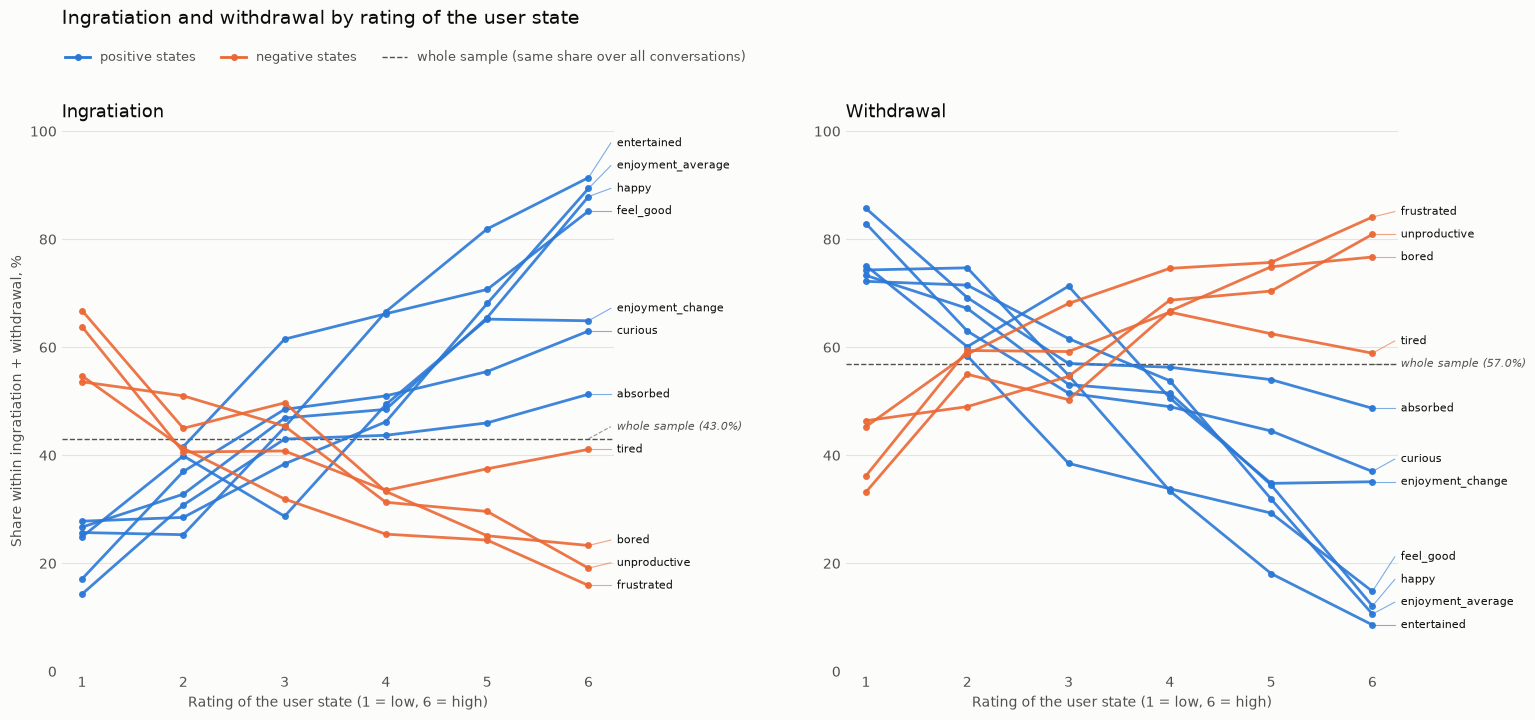

In [30]:
RATINGS = [1, 2, 3, 4, 5, 6]


def share_by_rating(df: pd.DataFrame, behavior: str, category: str, scales: list[str]) -> pd.DataFrame:
    """Share (%) of `category` within its opposite pair, for each scale (rows) and rating 1-6 (columns).

    :param df: the Oxford table
    :param behavior: behaviour facet id
    :param category: behaviour category whose share is computed
    :param scales: user scale ids
    """
    pair = list(BEHAVIOR_PAIR)
    rows = {}
    for scale in scales:
        counts = count_table(df, behavior, scale)[SCALE_VALUES]
        total = counts.loc[pair].sum(axis="index", min_count=1)
        share = (counts.loc[category] / total * 100).where(total >= MIN_POINT)
        rows[scale.removeprefix("user_")] = share.to_numpy()
    return pd.DataFrame(rows, index=RATINGS).T.round(1)


def reference_share(df: pd.DataFrame, behavior: str, category: str) -> float:
    """Share (%) of `category` within its opposite pair over the whole sample.

    :param df: the Oxford table
    :param behavior: behaviour facet id
    :param category: behaviour category
    """
    sizes = df.loc[(df["facet_id"] == behavior) & (df["level"] == 0)].set_index("cluster_name")["num_records"]
    return sizes[category] / sizes[list(BEHAVIOR_PAIR)].sum() * 100


def spread_labels(ends: pd.Series, min_gap: float, low: float, high: float) -> pd.Series:
    """Move label heights apart so that no two are closer than min_gap.

    :param ends: label heights (index = labels)
    :param min_gap: minimum vertical distance between labels
    :param low: lowest allowed height
    :param high: highest allowed height
    """
    placed = ends.sort_values().copy()
    for i in range(1, len(placed)):  # push up
        placed.iloc[i] = max(placed.iloc[i], placed.iloc[i - 1] + min_gap)
    placed.iloc[-1] = min(placed.iloc[-1], high)
    for i in range(len(placed) - 2, -1, -1):  # push back down from the top
        placed.iloc[i] = min(placed.iloc[i], placed.iloc[i + 1] - min_gap)
    return placed.clip(lower=low)


def rating_lines_panel(ax: plt.Axes, table: pd.DataFrame, reference: float, title: str) -> None:
    """One line per user scale across ratings 1-6, coloured by state group, labelled at the end.
    The dashed line (whole-sample share) is labelled in the same column as the scales.

    :param ax: axes to draw on
    :param table: output of share_by_rating
    :param reference: whole-sample share (dashed line)
    :param title: panel title
    """
    style_axes(ax)
    ax.axhline(reference, color=MUTED, linewidth=1, linestyle="--", zorder=1)
    ends = {"whole sample": (6, reference, MUTED)}  # the dashed line gets its own end label
    for group, states in STATE_GROUPS.items():
        for state in states:
            line = table.loc[state].dropna()
            if line.empty:
                continue
            ax.plot(line.index, line.to_numpy(), color=GROUP_COLORS[group], linewidth=2,
                    marker="o", markersize=4, alpha=0.9, zorder=3)
            ends[state] = (line.index[-1], line.iloc[-1], GROUP_COLORS[group])
    heights = spread_labels(pd.Series({s: e[1] for s, e in ends.items()}), min_gap=4.2, low=2, high=98)
    for state, (x_end, y_end, color) in ends.items():
        reference_line = state == "whole sample"
        ax.plot([x_end, 6.22], [y_end, heights[state]], color=color, linewidth=0.8, alpha=0.6,
                linestyle="--" if reference_line else "-", zorder=2)
        text = f"whole sample ({reference:.1f}%)" if reference_line else state
        ax.text(6.28, heights[state], text, color=MUTED if reference_line else INK, fontsize=8,
                va="center", style="italic" if reference_line else "normal")
    ax.set_title(title, color=INK, loc="left", fontsize=13, pad=10)
    ax.set_xticks(RATINGS)
    ax.set_xlim(0.8, 6.25)
    ax.set_ylim(0, 100)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


RATING_TABLES, REFERENCE_SHARES = {}, {}
for category in BEHAVIOR_PAIR:  # ingratiation, withdrawal
    RATING_TABLES[category] = share_by_rating(OX, BEHAVIOR, category, USER_SCALES)
    RATING_TABLES[category].to_csv(TABLE_DIR / f"08_{category}_by_rating.csv", encoding="utf-8-sig")
    REFERENCE_SHARES[category] = reference_share(OX, BEHAVIOR, category)
    print(f"Whole-sample {category} share within the pair: {REFERENCE_SHARES[category]:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(16, 7.4), facecolor=SURFACE)
for ax, category in zip(axes, BEHAVIOR_PAIR):
    rating_lines_panel(ax, RATING_TABLES[category], REFERENCE_SHARES[category], category.capitalize())
    ax.set_xlabel("Rating of the user state (1 = low, 6 = high)", color=MUTED)
axes[0].set_ylabel("Share within ingratiation + withdrawal, %", color=MUTED)
handles = [plt.Line2D([], [], color=c, linewidth=2, marker="o", markersize=4, label=f"{g} states")
           for g, c in GROUP_COLORS.items()]
handles.append(plt.Line2D([], [], color=MUTED, linewidth=1, linestyle="--",
                          label="whole sample (same share over all conversations)"))
fig.suptitle("Ingratiation and withdrawal by rating of the user state", color=INK, fontsize=14,
             x=0.055, ha="left", y=0.985)
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.05, 0.945), ncol=3,
           frameon=False, labelcolor=MUTED, fontsize=9)
fig.subplots_adjust(left=0.055, right=0.89, top=0.82, bottom=0.09, wspace=0.42)
save_figure(fig, "fig3_ingratiation_withdrawal_by_rating")

## 9. Motivation × four other behaviour facets

The eight motivation groups are described on four other behaviour facets (`PROFILE_FACETS`), with all their categories. Because the data holds two-way tables only, every number describes a **whole motivation group**; it is not restricted to the conversations of that group that were labelled ingratiation or withdrawal.

For one behaviour facet:

- `level1_counts` reads the cross-tab counts (`<facet>:<category>_num_records`) from the level-1 motivation rows. Suppressed cells stay empty (`NaN`).
- `whole_sample` reads the number of conversations in each category from the facet's own rows (level 0): the whole-sample reference.
- `profile` keeps the groups in the order of section 6 (`GROUP_ORDER`, highest ingratiation share first) and converts counts to percentages of the facet's categories. A group's percentages are computed over its counted conversations; a suppressed cell counts as 0 in the denominator and stays empty. `difference` = group % − whole-sample % (percentage points).

The `assert` checks that the categories found in the cross-tab columns are exactly the ones listed in `PROFILE_FACETS`.

In [31]:
GROUP_ORDER = list(MIX.drop(index="All").sort_values(BEHAVIOR_PAIR[0], ascending=False).index)


def level1_counts(rows: pd.DataFrame, facet: str) -> pd.DataFrame:
    """Counts of every category of `facet` within each level-1 group.

    :param rows: level-1 rows indexed by group name
    :param facet: behaviour facet id
    :return: rows = groups, columns = categories (NaN = suppressed)
    """
    prefix, suffix = f"{facet}:", "_num_records"
    cols = [c for c in rows.columns if c.startswith(prefix) and c.endswith(suffix)]
    counts = rows[cols].copy()
    counts.columns = [c.removeprefix(prefix).removesuffix(suffix) for c in cols]
    return counts


def whole_sample(df: pd.DataFrame, facet: str) -> pd.Series:
    """Conversations per category of `facet` in the whole subset (from the facet's own rows).

    :param df: the Oxford table
    :param facet: behaviour facet id
    """
    rows = df.loc[(df["facet_id"] == facet) & (df["level"] == 0)]
    return rows.set_index("cluster_name")["num_records"]


def profile(df: pd.DataFrame, facet: str, categories: list[str]) -> dict[str, pd.DataFrame]:
    """Counts, percentages and differences from the whole sample for every motivation group.

    :param df: the Oxford table
    :param facet: behaviour facet id
    :param categories: categories in display order
    :return: dict with "counts", "pct", "whole_pct", "difference"
    """
    counts_all = level1_counts(LEVEL1, facet)
    assert set(counts_all.columns) == set(categories), f"{facet}: categories {sorted(counts_all.columns)}"
    counts = counts_all.loc[GROUP_ORDER, categories]
    pct = counts.div(counts.fillna(0).sum(axis="columns"), axis="index") * 100
    whole = whole_sample(df, facet)[categories]
    whole_pct = whole / whole.sum() * 100
    return {"counts": counts, "pct": pct.round(1), "whole_pct": whole_pct.round(1),
            "difference": (pct - whole_pct).round(1)}


PROFILES = {}
for facet, categories in PROFILE_FACETS.items():
    result = profile(OX, facet, categories)
    PROFILES[facet] = result
    table = pd.concat(
        {"count": result["counts"], "pct": result["pct"], "difference": result["difference"]},
        axis="columns",
    )
    table.loc["whole sample", "pct"] = result["whole_pct"].to_numpy()
    table.index.name = "motivation group"
    table.to_csv(TABLE_DIR / f"09_profile__{facet.removeprefix('model_')}.csv", encoding="utf-8-sig")
    n_suppressed = int(result["counts"].isna().to_numpy().sum())
    print(f"{facet:<32} {n_suppressed} suppressed cell(s)")

model_flattery_challenge         0 suppressed cell(s)
model_assent_dissent             0 suppressed cell(s)
model_conformism_eccentricity    0 suppressed cell(s)
model_refusal_compliance         0 suppressed cell(s)


Combined view: group percentage per category, with the whole-sample percentage in the last row (one block of columns per facet).

In [32]:
COMBINED = pd.concat(
    {FACET_TITLES[f]: pd.concat([r["pct"], r["whole_pct"].to_frame("whole sample").T])
     for f, r in PROFILES.items()},
    axis="columns",
)
COMBINED.rename(columns=lambda c: CATEGORY_NAMES.get(c, c), level=1)

Flattery / challenge              \
                                                  flattery mixed   n/a   
Longing and emotional yearning                        21.9  39.8  33.4   
Acute overwhelm and distress                           7.8  40.8  39.7   
Ambitious motivated enthusiasm                        12.1  26.7  54.1   
Anxiety and reassurance-seeking                        8.7  32.1  46.5   
Intellectual curiosity and wonder                      7.4  16.7  68.5   
Perfectionist quality anxiety                          9.8  19.1  57.2   
Impatient task frustration                             5.2  12.7  66.6   
Detached pragmatic efficiency-seeking                  5.6   9.9  79.1   
whole sample                                           8.0  19.2  62.4   

                                                Assent / dissent        \
                                      challenge           assent   n/a   
Longing and emotional yearning              4.9             38.3  35.1   
Acute overwhelm and distress               11.6             40.2  33.0   
Ambitious motivated enthusiasm              7.1             40.5  46.0   
Anxiety and reassurance-seeking            12.7             36.8  38.0   
Intellectual curiosity and wonder           7.3             26.3  60.4   
Perfectionist quality anxiety              13.9             39.0  40.6   
Impatient task frustration                 15.5             29.5  52.3   
Detached pragmatic efficiency-seeking       5.5             25.5  67.0   
whole sample                               10.5             32.5  51.4   

                                              Conformism / eccentricity        \
                                      dissent                conformism   n/a   
Longing and emotional yearning           26.7                      61.0   6.8   
Acute overwhelm and distress             26.8                      67.9   6.4   
Ambitious motivated enthusiasm           13.5                      71.6  13.8   
Anxiety and reassurance-seeking          25.2                      72.5   8.8   
Intellectual curiosity and wonder        13.3                      69.0  10.8   
Perfectionist quality anxiety            20.4                      77.1  12.0   
Impatient task frustration               18.1                      76.8  11.9   
Detached pragmatic efficiency-seeking     7.5                      68.6  20.3   
whole sample                             16.2                      72.2  13.4   

                                                   Refusal / compliance        \
                                      eccentricity              refusal   n/a   
Longing and emotional yearning                32.2                  5.9  18.9   
Acute overwhelm and distress                  25.7                  4.0  18.2   
Ambitious motivated enthusiasm                14.6                  2.0  11.0   
Anxiety and reassurance-seeking               18.7                  2.8  12.9   
Intellectual curiosity and wonder             20.1                  2.5  15.9   
Perfectionist quality anxiety                 10.9                  1.2   9.0   
Impatient task frustration                    11.3                  2.6  10.0   
Detached pragmatic efficiency-seeking         11.1                  2.0  16.7   
whole sample                                  14.4                  2.7  12.8   

                                                  
                                      compliance  
Longing and emotional yearning              75.1  
Acute overwhelm and distress                77.8  
Ambitious motivated enthusiasm              86.9  
Anxiety and reassurance-seeking             84.2  
Intellectual curiosity and wonder           81.7  
Perfectionist quality anxiety               89.8  
Impatient task frustration                  87.4  
Detached pragmatic efficiency-seeking       81.2  
whole sample                                84.5

**Figure 4.** One heatmap panel per behaviour facet, all categories included. Rows = the eight groups in `GROUP_ORDER` (highest ingratiation share first, as in Figure 1); each row label gives the group size. Each cell shows the difference from the whole sample in percentage points, as in Figure 1; the groups' own percentages are in the saved tables (`09_profile__*.csv`). The column header gives the whole-sample percentage. All panels share one symmetric colour scale, so equal colours mean equal differences across facets. Suppressed cells are hatched grey and empty.

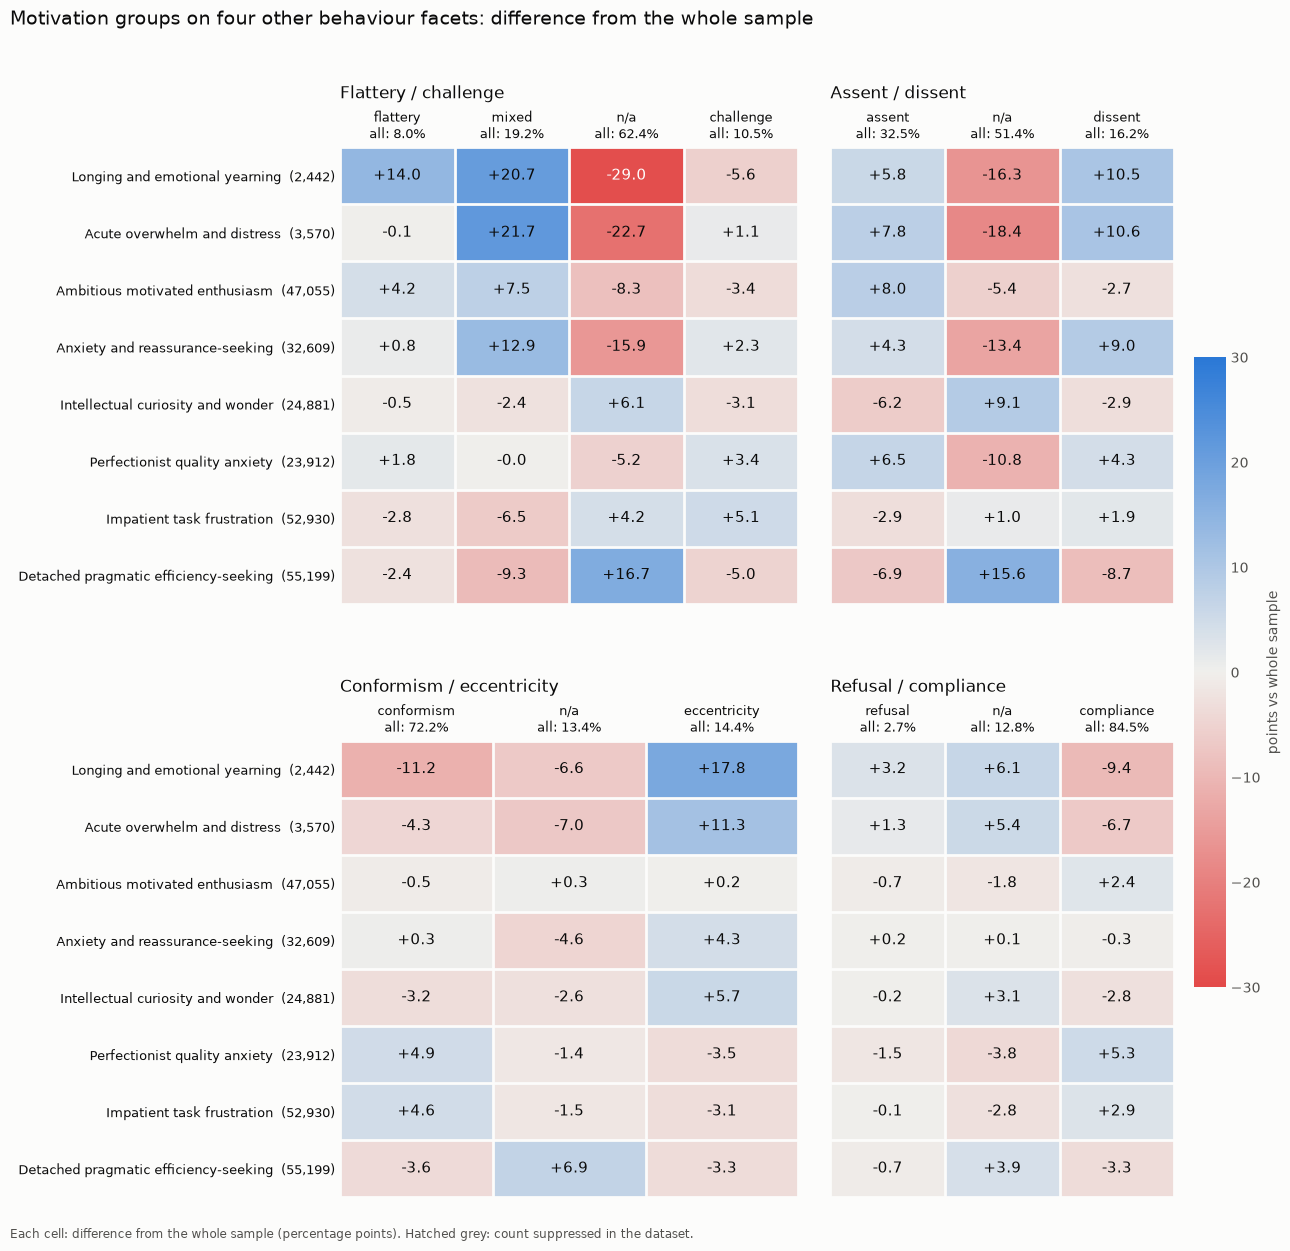

In [33]:
def profile_panel(ax: plt.Axes, result: dict, title: str, limit: float, show_rows: bool):
    """Draw one facet's difference heatmap on `ax`.

    :param ax: axes to draw on
    :param result: output of profile for one facet
    :param title: panel title
    :param limit: colour-scale limit (points), shared by all panels
    :param show_rows: True to print the group names on the y axis
    :return: the image, used for the shared colour bar
    """
    diff = result["difference"]
    ax.set_facecolor(SURFACE)
    image = ax.imshow(diff.to_numpy(dtype=float), cmap=DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
    for i in range(diff.shape[0]):
        for j in range(diff.shape[1]):
            value = diff.iat[i, j]
            if pd.isna(value):
                ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor="#d9d8d3",
                                           hatch="///", edgecolor=SURFACE, linewidth=0))
                continue
            color = text_color_on(DIVERGING((value + limit) / (2 * limit)))
            ax.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=10.5, color=color)
    headers = [f"{CATEGORY_NAMES.get(c, c)}\nall: {result['whole_pct'][c]:.1f}%" for c in diff.columns]
    ax.set_xticks(range(diff.shape[1]), headers, color=INK, fontsize=9)
    ax.xaxis.tick_top()
    sizes = LEVEL1["num_records"]
    labels = [f"{g}  ({sizes[g]:,})" for g in diff.index] if show_rows else [""] * len(diff)
    ax.set_yticks(range(diff.shape[0]), labels, color=INK, fontsize=9.5)
    ax.set_xticks(np.arange(-0.5, diff.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, diff.shape[0]), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.tick_params(which="both", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(title, color=INK, loc="left", fontsize=12, pad=8)
    return image


all_diffs = np.concatenate([r["difference"].to_numpy(dtype=float).ravel() for r in PROFILES.values()])
LIMIT = max(10, np.ceil(np.nanmax(np.abs(all_diffs)) / 5) * 5)

fig, axes = plt.subplots(2, 2, figsize=(15, 12.5), facecolor=SURFACE, gridspec_kw={"width_ratios": [4, 3]})
for k, (ax, (facet, result)) in enumerate(zip(axes.flat, PROFILES.items())):
    image = profile_panel(ax, result, FACET_TITLES[facet], LIMIT, show_rows=(k % 2 == 0))
fig.suptitle("Motivation groups on four other behaviour facets: difference from the whole sample",
             color=INK, fontsize=14, x=0.01, ha="left", y=0.99)
fig.subplots_adjust(left=0.23, right=0.9, top=0.88, bottom=0.04, wspace=0.08, hspace=0.3)
bar = fig.colorbar(image, ax=axes, shrink=0.6, pad=0.02)
bar.set_label("points vs whole sample", color=MUTED)
bar.ax.tick_params(colors=MUTED, length=0)
bar.outline.set_visible(False)
fig.text(0.01, 0.005, "Each cell: difference from the whole sample (percentage points). "
         "Hatched grey: count suppressed in the dataset.", color=MUTED, fontsize=8.5, ha="left", va="bottom")
save_figure(fig, "fig4_motivation_x_other_behaviours")

## 10. Integrity check and list of outputs

The fingerprint of `OX` is computed again and compared with the one stored at loading. If they differ, a cell modified the raw data and the notebook stops.

In [34]:
assert fingerprint(OX) == RAW_FINGERPRINT, "the raw Oxford table was modified"
print(f"Raw data unchanged (fingerprint {RAW_FINGERPRINT}).")

Raw data unchanged (fingerprint 41aa7efc2753).


All files written by this notebook, relative to `outputs/`. Tables are numbered by the section that creates them: 01–02 = section 3, 03–04 = section 5, 05–06 = section 6, 07 = section 7, 08 = section 8, 09 = section 9. Figures are numbered as in the report: `fig1` = Figure 1, `fig2` = Figure 2, `fig3` = Figure 3, `fig4` = Figure 4; `supp1_known_groups` = Supplementary S1.

In [35]:
OUTPUT_FILES = sorted(p.relative_to(OUTPUT_DIR).as_posix() for p in OUTPUT_DIR.rglob("*") if p.is_file())
print(f"{len(OUTPUT_FILES)} files in {OUTPUT_DIR}/")
for name in OUTPUT_FILES:
    print("  ", name)

63 files in outputs/
   figures/fig1_motivation_x_ingratiation.png
   figures/fig2_rated_minus_unrated.png
   figures/fig3_ingratiation_withdrawal_by_rating.png
   figures/fig4_motivation_x_other_behaviours.png
   figures/supp1_known_groups.png
   tables/01_facet_overview.csv
   tables/02_crosstab_facets.csv
   tables/03_behaviour_facets.csv
   tables/04_label_meaning__x__assent_dissent.csv
   tables/04_label_meaning__x__conformism_eccentricity.csv
   tables/04_label_meaning__x__encouragement_discouragement.csv
   tables/04_label_meaning__x__espousal_facts_norms.csv
   tables/04_label_meaning__x__flattery_challenge.csv
   tables/04_label_meaning__x__refusal_compliance.csv
   tables/04_label_profile.csv
   tables/05_motivation_groups.csv
   tables/06_motivation_x_ingratiation.csv
   tables/06_motivation_x_ingratiation_v.csv
   tables/07_known_groups_motivation.csv
   tables/07_scale_selection.csv
   tables/07_user_facet_distribution.csv
   tables/08_ingratiation_by_rating.csv
   tables/